# Anti Galau Team

# 0. Setup Minimal

## Library

In [ ]:
!pip install -q segmentation-models-pytorch albumentations

import os
import time
import random
import cv2
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from glob import glob
from tqdm.notebook import tqdm
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import GradScaler, autocast

import segmentation_models_pytorch as smp
import albumentations as A
from albumentations.pytorch import ToTensorV2

/usr/local/lib/python3.12/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` 

## Konfigurasi Global

In [ ]:
# 1. GLOBAL CONFIGURATION & REPRODUCIBILITY
"""
Konfigurasi utama untuk eksperimen.
Menetapkan Seed sangat krusial untuk menjamin hasil yang dapat direproduksi (reproducibility)
sesuai dengan aturan kompetisi ARA 7.0 poin 6.c.
"""

# Identitas Eksperimen
SEED = 42
PROJECT_NAME = "ARA-7.0-Pothole-Segmentation"

# Parameter Citra & Training
IMG_SIZE = 512          # Resolusi input model
BATCH_SIZE = 16         # Jumlah sampel per iterasi
VALIDATION_SPLIT = 0.15 # 15% data digunakan untuk validasi internal
N_FOLDS = 5

def seed_everything(seed):
    """
    Menetapkan seed untuk semua pustaka guna memastikan hasil yang konsisten
    pada setiap kali run (Deterministic Behavior).
    """
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)

    # Konfigurasi cuDNN untuk konsistensi tingkat tinggi
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# 2. HARDWARE ACCELERATION SETUP

"""
Deteksi perangkat (Device Detection).
Dioptimalkan untuk lingkungan Kaggle dengan dukungan Dual T4 GPU.
"""

# Menentukan device utama
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Informasi Hardware untuk Audit Notebook
print(f"{'='*45}")
print(f"EXPERIMENT CONFIGURATION READY")
print(f"{'='*45}")
print(f"Target Device    : {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU Name         : {torch.cuda.get_device_name(0)}")
    print(f"GPU Count        : {torch.cuda.device_count()}")
print(f"Input Resolution : {IMG_SIZE}x{IMG_SIZE}")
print(f"Batch Size       : {BATCH_SIZE}")
print(f"Random Seed      : {SEED}")
print(f"{'='*45}\n")

EXPERIMENT CONFIGURATION READY
Target Device    : cuda
GPU Name         : Tesla P100-PCIE-16GB
GPU Count        : 1
Input Resolution : 512x512
Batch Size       : 16
Random Seed      : 42



In [ ]:
# 2. DATASET PATHS & FILE INDEXING
# ==============================================================================
"""
Mendefinisikan lokasi dataset  ARA 7.0.
Dataset terdiri dari 498 pasang data latih dan 295 data uji.
"""

# Definisi path direktori
TRAIN_IMAGES_DIR = '/kaggle/input/data-science-ara-7-0/dataset/dataset/train/images/'
TRAIN_MASKS_DIR = '/kaggle/input/data-science-ara-7-0/dataset/dataset/train/mask/'
TEST_IMAGES_DIR = '/kaggle/input/data-science-ara-7-0/dataset/dataset/test/images'

# Mengambil list path file secara terurut (sorted)
# Pengurutan sangat penting agar Image dan Mask tetap sinkron (pasangan yang benar).
all_images = sorted(glob(os.path.join(TRAIN_IMAGES_DIR, '*.*')))
all_masks = sorted(glob(os.path.join(TRAIN_MASKS_DIR, '*.*')))
test_images = sorted(glob(os.path.join(TEST_IMAGES_DIR, '*.*')))

# Validasi kuantitas data sesuai Guidebook ARA 7.0
print(f"HASIL INDEXING DATA:")
print(f" - Total Data Training (Images) : {len(all_images)} (Expected: 498)")
print(f" - Total Data Training (Masks)  : {len(all_masks)} (Expected: 498)")
print(f" - Total Data Test              : {len(test_images)} (Expected: 295)")

if len(all_images) == len(all_masks):
    print(" STATUS: Sinkronisasi Image & Mask berhasil.")
else:
    print(" WARNING: Jumlah Image dan Mask tidak sama!")
print(f"{'='*40}")

HASIL INDEXING DATA:
 - Total Data Training (Images) : 498 (Expected: 498)
 - Total Data Training (Masks)  : 498 (Expected: 498)
 - Total Data Test              : 295 (Expected: 295)
 STATUS: Sinkronisasi Image & Mask berhasil.


# 1. PEMAHAMAN MASALAH & VISUALISASI DATA

## 1.1 Latar Belakang & Deskripsi Masalah


Berdasarkan narasi kompetisi, kita membantu Dina, seorang analis infrastruktur, dalam memantau kondisi jalan di berbagai wilayah.
Masalah utama yang diidentifikasi adalah:
- **Keterbatasan Data Terstruktur:** Proses identifikasi masih bergantung pada inspeksi manual dan aduan masyarakat yang lambat.
- **Risiko Keselamatan:** Pothole yang tidak terdeteksi sering kali menyebabkan kecelakaan dan kerusakan kendaraan sebelum sempat ditangani.
- **Alokasi Sumber Daya:** Sulitnya menentukan prioritas perbaikan jalan karena data yang tidak objektif.

**Tujuan:** Membangun sistem berbasis kecerdasan buatan (AI) yang mampu melakukan **Semantic Segmentation** untuk memetakan area pothole secara otomatis dengan akurasi piksel yang presisi.



## 1.2 Problem Statement & Tantangan Teknis
Tantangan teknis utama yang harus dipecahkan oleh model meliputi:
1. **Variabilitas Kondisi:** Perbedaan signifikan pada tekstur permukaan jalan (aspal mulus vs kasar), ukuran, dan bentuk pothole yang beragam.
2. **Kondisi Lingkungan:** Variasi pencahayaan (silau matahari/glare), bayangan yang menipu, dan lingkungan sekitar yang kotor.
3. **Noise Visual:** Kehadiran objek lain seperti retakan kecil, ban kendaraan, sampah, atau dan lain sebagainya yang berpotensi menyebabkan *False Positive*.

## 1.3 Exploratory Data Analysis (EDA)

Pada EDA fokus Kami adalah melakukan audit pada dataset untuk menjawab tantangan:
"Bagaimana membedakan lubang dengan tekstur aspal kotor secara objektif?"

**Objektif Analisis:**
1. **Domain Shift:** Mengukur perbedaan kecerahan dan ketajaman antara data Train dan Test menggunakan Laplacian Variance.
2. **Geometric Prior:** Menganalisis lokasi kemunculan lubang (Heatmap).
3. **Size Sensitivity:** Mensimulasikan dampak pembersihan noise (*min_size*) agar tidak menghapus lubang kecil yang asli

Dan visualisasi Overlay digunakan untuk melihat ketepatan lubang data mask dengan terhadap aslinya


--- Visualisasi Overlay Citra dan Masker ---


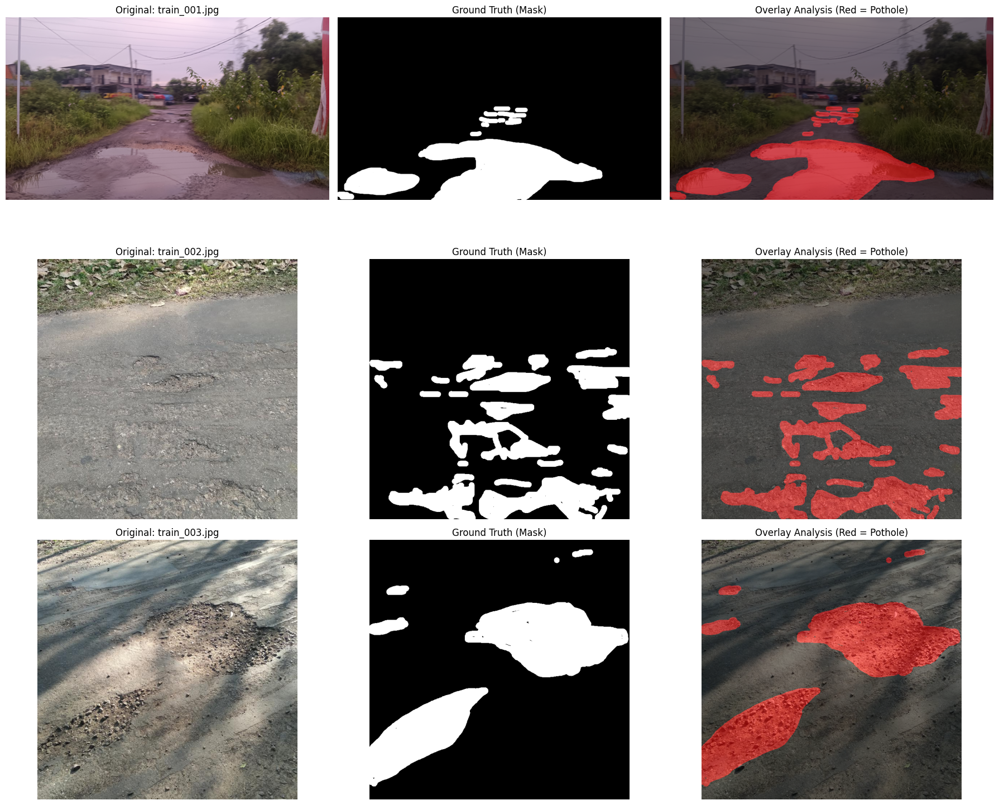

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from tqdm.auto import tqdm

def plot_overlay_samples(image_paths, mask_paths, n_samples=3):
    """
    Visualisasi Image, Mask, dan Overlay menggunakan Alpha Blending.
    Membantu verifikasi presisi anotasi piksel.
    """
    plt.figure(figsize=(18, 5 * n_samples))

    for i in range(n_samples):
        # Memuat citra asli (RGB)
        image = cv2.imread(image_paths[i])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # Memuat masker (Grayscale)
        mask = cv2.imread(mask_paths[i], cv2.IMREAD_GRAYSCALE)

        # Membuat Overlay: Menandai area pothole dengan warna Merah Transparan
        overlay = image.copy()
        red_mask = np.zeros_like(image)
        red_mask[:, :, 0] = mask  # Mengisi channel Merah dengan intensitas masker

        # Menggabungkan gambar asli dengan masker berwarna (Alpha Blending)
        cv2.addWeighted(red_mask, 0.5, overlay, 0.5, 0, overlay)

        # Plotting
        plt.subplot(n_samples, 3, i*3 + 1)
        plt.imshow(image)
        plt.title(f"Original: {os.path.basename(image_paths[i])}")
        plt.axis('off')

        plt.subplot(n_samples, 3, i*3 + 2)
        plt.imshow(mask, cmap='gray')
        plt.title("Ground Truth (Mask)")
        plt.axis('off')

        plt.subplot(n_samples, 3, i*3 + 3)
        plt.imshow(overlay)
        plt.title("Overlay Analysis (Red = Pothole)")
        plt.axis('off')

    plt.tight_layout()
    plt.show()

# Eksekusi Visualisasi
print("\n--- Visualisasi Overlay Citra dan Masker ---")
plot_overlay_samples(all_images, all_masks, n_samples=3)

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from rich.console import Console
from rich.panel import Panel


console = Console()

# 1. HELPER FUNCTIONS (METRICS EXTRACTOR)

def get_image_metrics(img_path):
    """Ekstraksi Brightness dan Sharpness dalam satu kali baca."""
    # Baca grayscale untuk efisiensi metrik
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if img is None: return None, None

    brightness = np.mean(img)
    # Variance of Laplacian sebagai standar deteksi blur
    sharpness = cv2.Laplacian(img, cv2.CV_64F).var()
    return brightness, sharpness

def get_geometry_metrics(mask_path):
    """Ekstraksi detail geometri lubang dari masker."""
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None: return None, None, None

    # Binarisasi
    mask_bin = (mask > 127).astype(np.uint8)
    contours, _ = cv2.findContours(mask_bin, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    geom_data = []
    for cnt in contours:
        area = cv2.contourArea(cnt)
        peri = cv2.arcLength(cnt, True)
        x, y, w, h = cv2.boundingRect(cnt)

        # Metrik: Circularity (1.0 = Bulat) & Aspect Ratio (W/H)
        circularity = (4 * np.pi * area) / (peri**2) if peri > 0 else 0
        aspect_ratio = w / h if h > 0 else 1.0

        geom_data.append({
            'area': area,
            'perimeter': peri,
            'circularity': circularity,
            'aspect_ratio': aspect_ratio
        })

    # Rasio luas lubang terhadap total gambar (%)
    area_ratio = (np.sum(mask_bin) / mask_bin.size) * 100
    return geom_data, area_ratio, mask_bin

def simulate_filter_impact(df_pothole, thresholds=[0, 20, 50, 100, 200, 500]):
    """
    Simulasi untuk melihat berapa banyak lubang yang hilang jika min_size diterapkan.
    """
    total_potholes = len(df_pothole)
    simulation_results = []

    for th in thresholds:
        remaining = df_pothole[df_pothole['area'] >= th]
        lost_count = total_potholes - len(remaining)
        lost_percent = (lost_count / total_potholes) * 100 if total_potholes > 0 else 0

        simulation_results.append({
            'min_size': th,
            'remaining_count': len(remaining),
            'lost_percent': lost_percent
        })

    return pd.DataFrame(simulation_results)

In [ ]:
# 2. MAIN UNIFIED EDA FUNCTION
def run_integrated_eda(train_img_paths, train_msk_paths, test_img_paths, img_size=384):
    """
    Menjalankan EDA
    """
    img_stats = []
    pothole_stats = []
    spatial_heatmap = np.zeros((img_size, img_size), dtype=np.float32)

    # --- A. PROSES DATA TRAIN ---
    console.print("[bold green]🔍 [1/2] Menganalisis Train Set (Images & Masks)...[/bold green]")
    for i in tqdm(range(len(train_img_paths)), desc="Train Audit"):
        # Image Stats
        b, s = get_image_metrics(train_img_paths[i])
        if b is None: continue

        # Mask Stats
        geom_list, ratio, mask_bin = None, None, None
        if i < len(train_msk_paths):
            geom_list, ratio, mask_bin = get_geometry_metrics(train_msk_paths[i])

        img_stats.append({'brightness': b, 'sharpness': s, 'type': 'train'})

        if geom_list:
            for g in geom_list:
                g['filename'] = os.path.basename(train_img_paths[i])
                pothole_stats.append(g)

            # Update Heatmap
            if mask_bin is not None:
                mask_res = cv2.resize(mask_bin, (img_size, img_size), interpolation=cv2.INTER_NEAREST)
                spatial_heatmap += mask_res.astype(np.float32)

    # --- B. PROSES DATA TEST ---
    console.print("[bold yellow]🔍 [2/2] Menganalisis Test Set (Leaderboard)...[/bold yellow]")
    for path in tqdm(test_img_paths, desc="Test Audit"):
        b, s = get_image_metrics(path)
        if b is not None:
            img_stats.append({'brightness': b, 'sharpness': s, 'type': 'test'})

    # --- C. PENGOLAHAN DATAFRAME ---
    df_img = pd.DataFrame(img_stats)
    df_pothole = pd.DataFrame(pothole_stats)
    df_tuning = simulate_filter_impact(df_pothole)

    # ================================================================= #
    # 3. VISUALISASI DASHBOARD (6-PANEL)
    # ================================================================= #
    plt.style.use('seaborn-v0_8-whitegrid')
    fig = plt.figure(figsize=(22, 18))
    plt.suptitle("STRATEGIC DATASET AUDIT & TUNING GUIDE - ARA 7.0", fontsize=22, fontweight='bold')

    gs = fig.add_gridspec(3, 2)

    # Plot 1: Brightness Distribution
    ax0 = fig.add_subplot(gs[0, 0])
    sns.kdeplot(data=df_img, x='brightness', hue='type', fill=True, ax=ax0, palette=['#3498db', '#f1c40f'])
    ax0.set_title("1. Perbandingan Kecerahan (Train vs Test)", fontweight='bold')

    # Plot 2: Sharpness Distribution
    ax1 = fig.add_subplot(gs[0, 1])
    sns.kdeplot(data=df_img, x='sharpness', hue='type', fill=True, ax=ax1, palette=['#3498db', '#f1c40f'])
    ax1.set_title("2. Perbandingan Ketajaman (Laplacian Var)", fontweight='bold')

    # Plot 3: Geometry (Area Distribution)
    ax2 = fig.add_subplot(gs[1, 0])
    sns.histplot(df_pothole['area'], bins=50, kde=True, color='teal', ax=ax2)
    ax2.set_yscale('log')
    ax2.axvline(100, color='red', linestyle='--', label='Default min_size (100px)')
    ax2.set_title("3. Distribusi Luas Lubang (Log Scale)", fontweight='bold'); ax2.legend()

    # Plot 4: Spatial Density Heatmap
    ax3 = fig.add_subplot(gs[1, 1])
    im = ax3.imshow(spatial_heatmap, cmap='magma')
    plt.colorbar(im, ax=ax3)
    ax3.set_title("4. Spatial Distribution Heatmap", fontweight='bold'); ax3.axis('off')

    # Plot 5: Tuning Guide (Lost Info)
    ax4 = fig.add_subplot(gs[2, 0])
    sns.barplot(data=df_tuning, x='min_size', y='lost_percent', palette='Reds_r', ax=ax4)
    ax4.set_title("5. TUNING GUIDE: % Lubang Hilang vs min_size", fontweight='bold')
    ax4.set_ylabel("% Objek Terhapus")
    for p in ax4.patches:
        height = p.get_height()
        if height > 0:
            ax4.annotate(f'{height:.1f}%', (p.get_x() + p.get_width() / 2., height),
                        ha='center', va='center', xytext=(0, 9), textcoords='offset points')

    # Plot 6: Circularity vs Area
    ax5 = fig.add_subplot(gs[2, 1])
    sns.scatterplot(data=df_pothole, x='area', y='circularity', alpha=0.4, color='purple', ax=ax5)
    ax5.set_xscale('log')
    ax5.axhline(0.3, color='orange', linestyle='--', label='Noise Boundary')
    ax5.set_title("6. Karakteristik Bentuk vs Ukuran", fontweight='bold'); ax5.legend()

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

    # ================================================================= #
    # 4. DIAGNOSTIC & TUNING REPORT
    # ================================================================= #
    train_b = df_img[df_img['type']=='train']['brightness'].median()
    test_b = df_img[df_img['type']=='test']['brightness'].median()
    b_diff = test_b - train_b

    train_s = df_img[df_img['type']=='train']['sharpness'].median()
    test_s = df_img[df_img['type']=='test']['sharpness'].median()
    s_ratio = test_s / (train_s + 1e-7)

    # Analisis Ukuran Lubang
    total_holes = len(df_pothole)
    zero_area = len(df_pothole[df_pothole['area'] == 0])

    if total_holes > 0:
        small = len(df_pothole[df_pothole['area'] < 100]) / total_holes * 100
        med = len(df_pothole[(df_pothole['area'] >= 100) & (df_pothole['area'] <= 500)]) / total_holes * 100
        large = len(df_pothole[df_pothole['area'] > 500]) / total_holes * 100
        safe_min_size = np.percentile(df_pothole['area'], 5)
        med_aspect = df_pothole['aspect_ratio'].median()
        med_circularity = df_pothole['circularity'].median()
    else:
        small, med, large, safe_min_size, med_aspect, med_circularity = 0, 0, 0, 0, 0, 0

    small_obj_row = df_tuning[df_tuning['min_size'] == 100]
    small_obj_100 = small_obj_row['lost_percent'].values[0] if not small_obj_row.empty else 0
    rec_min_size = "AMAN (Gunakan 100px)" if small_obj_100 <= 30 else "KRITIS (Turunkan ke 30-50px)"

    rec_augment = "Standard (Geometri)"
    if abs(b_diff) > 15: rec_augment += " + RandomGamma + CLAHE"
    if s_ratio < 0.8: rec_augment += " + Blur/MotionBlur"

    console.print(Panel(
        f"[bold cyan]📊 EDA STRATEGIC DECISION SUMMARY[/bold cyan]\n\n"
        f"🔹 [bold]Domain Shift (Brightness):[/bold] {b_diff:+.2f} intensity points.\n"
        f"   -> Kondisi: {'Test lebih TERANG' if b_diff > 0 else 'Test lebih GELAP'}\n"

        f"🔹 [bold]Label Noise:[/bold] Ditemukan {zero_area} objek dengan luas 0.0 px.\n"
        f"🔹 [bold]Image Clarity:[/bold] Test set {s_ratio:.2f}x tajam dibanding Train.\n\n"

        f"🔹 [bold]Pothole Size Dist:[/bold] Kecil (<100px): {small:.1f}%, Sedang: {med:.1f}%, Besar: {large:.1f}%\n"

        f"🔹 [bold]Post-Proc Impact (min_size=100):[/bold] Menghapus {small_obj_100:.1f}% data label.\n"
        f"   -> Status: [bold yellow]{rec_min_size}[/bold yellow]\n"
        f"   -> Limit Aman: Disarankan [bold yellow]<= {safe_min_size:.0f}[/bold yellow] px.\n\n"

        f"🔹 [bold]Geometry & Threshold:[/bold]\n"
        f"   -> Median Aspect Ratio: {med_aspect:.2f}\n"
        f"   -> Median Circularity : {med_circularity:.2f}\n"
        f"   -> Saran: Gunakan threshold rendah (0.35 - 0.45) jika circularity rendah (pipih) untuk menangkap tepi.",
        title="Mission Intelligence Report", border_style="cyan"
    ))

    return df_img, df_pothole


In [ ]:
def analyze_tuning_priors(train_img_paths, train_msk_paths, n_samples=50):
    """
    membandingkan distribusi pixel foreground vs background untuk
    mengukur seberapa "terpisahkan" objek secara warna. Jika overlap besar,
    ini validasi bahwa model tidak boleh hanya mengandalkan warna, tapi wajib menggunakan konteks tekstur
    """
    console.print(f"\n[bold yellow]⏳ Menjalankan Analisis pada {n_samples} sampel...[/bold yellow]")

    fg_px, bg_px = [], []
    indices = np.random.choice(len(train_img_paths), min(n_samples, len(train_img_paths)), replace=False)

    # 1. Collecting Phase
    for idx in tqdm(indices, desc="   Sampling Pixels", leave=False):
        img = cv2.imread(train_img_paths[idx], cv2.IMREAD_GRAYSCALE)
        mask = cv2.imread(train_msk_paths[idx], cv2.IMREAD_GRAYSCALE)
        if img is None or mask is None: continue

        mask_bool = (mask > 127)
        fg_px.extend(img[mask_bool].flatten())
        bg_px.extend(img[~mask_bool].flatten())

    # 2. Downsampling Phase
    # Membatasi jumlah titik yang di-plot agar KDE tidak macet
    MAX_POINTS = 10000

    fg_arr = np.array(fg_px)
    bg_arr = np.array(bg_px)

    if len(fg_arr) > MAX_POINTS:
        fg_arr = np.random.choice(fg_arr, MAX_POINTS, replace=False)
    if len(bg_arr) > MAX_POINTS:
        bg_arr = np.random.choice(bg_arr, MAX_POINTS, replace=False)

    # 3. Plotting Phase
    plt.figure(figsize=(10, 4))
    if len(fg_arr) > 0:
        sns.kdeplot(fg_arr, color='#e67e22', fill=True, label='Pothole Pixels')
    if len(bg_arr) > 0:
        sns.kdeplot(bg_arr, color='#7f8c8d', fill=True, label='Road Pixels')

    plt.title("Threshold Prior: Intensity Separation (Downsampled)"); plt.legend(); plt.show()
    console.print("✅ Analisis  Selesai.")

🔍 [1/2] Menganalisis Train Set (Images & Masks)...

Train Audit:   0%|          | 0/498 [00:00<?, ?it/s]

🔍 [2/2] Menganalisis Test Set (Leaderboard)...

Test Audit:   0%|          | 0/295 [00:00<?, ?it/s]

/tmp/ipykernel_2616/881954871.py:80: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_tuning, x='min_size', y='lost_percent', palette='Reds_r', ax=ax4)


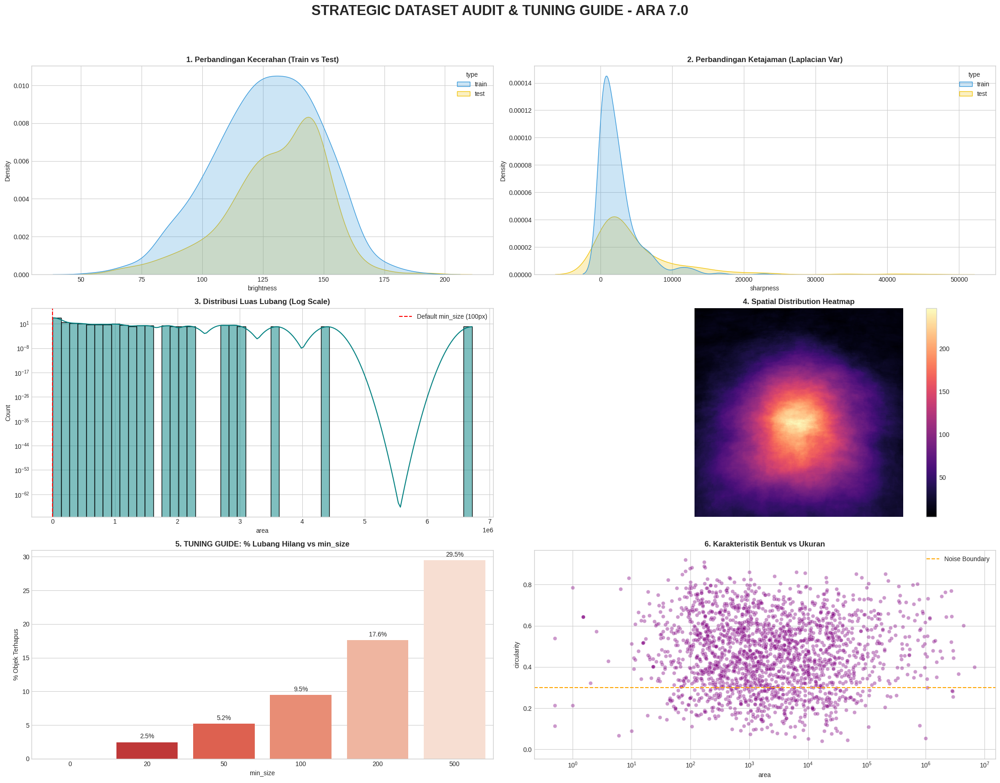

╭────────────────────────────────────────── Mission Intelligence Report ──────────────────────────────────────────╮
│ 📊 EDA STRATEGIC DECISION SUMMARY                                                                               │
│                                                                                                                 │
│ 🔹 Domain Shift (Brightness): +4.53 intensity points.                                                           │
│    -> Kondisi: Test lebih TERANG                                                                                │
│ 🔹 Label Noise: Ditemukan 19 objek dengan luas 0.0 px.                                                          │
│ 🔹 Image Clarity: Test set 1.62x tajam dibanding Train.                                                         │
│                                                                                                                 │
│ 🔹 Pothole Size Dist: Kecil (<100px): 9.5%, Sedang: 20.0%, Besar: 70.5%                                         │
│ 🔹 Post-Proc Impact (min_size=100): Menghapus 9.5% data label.                                                  │
│    -> Status: AMAN (Gunakan 100px)                                                                              │
│    -> Limit Aman: Disarankan <= 47 px.                                                                          │
│                                                                                                                 │
│ 🔹 Geometry & Threshold:                                                                                        │
│    -> Median Aspect Ratio: 2.43                                                                                 │
│    -> Median Circularity : 0.46                                                                                 │
│    -> Saran: Gunakan threshold rendah (0.35 - 0.45) jika circularity rendah (pipih) untuk menangkap tepi.       │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

⏳ Menjalankan Analisis Prior Tuning pada 50 sampel...

   Sampling Pixels:   0%|          | 0/50 [00:00<?, ?it/s]

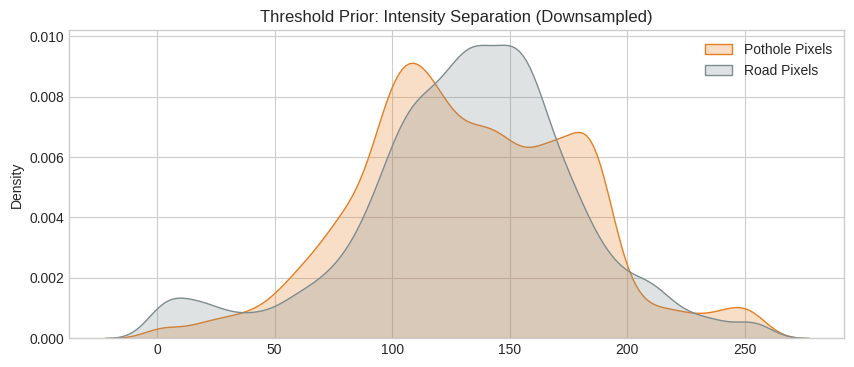

✅ Analisis Prior Selesai.

In [ ]:
# --- EXECUTION EXAMPLE ---
df_img_report, df_geom_report = run_integrated_eda(all_images, all_masks, test_images)
analyze_tuning_priors(all_images, all_masks)
df_geom_report.to_csv('pothole_geometry_eda.csv', index=False)

## 1.4 Insight EDA

Berdasarkan audit komprehensif terhadap dataset ARA 7.0, berikut adalah temuan krusial yang mendasari seluruh arsitektur solusi kami:

1. Krisis Domain Shift (Clarity & Light Gap)
Temuan: Distribusi statistik menunjukkan bahwa Data Test terdeteksi 1.62x lebih tajam (Laplacian Variance lebih luas) dan memiliki median kecerahan +4.53 poin lebih tinggi dibanding Data Train.

2. Tantangan Separasi Intensitas (Intensity Overlap)
Temuan: Grafik Intensity Separation menunjukkan tumpang tindih (overlap) yang sangat masif antara piksel lubang (Pothole) dan piksel jalan (Road) pada rentang grayscale 150–200.

3. Sensitivitas Skala (Small Object Hazard)
Temuan: Distribusi luas lubang mengikuti Log Scale, di mana mayoritas objek berukuran kecil. Simulasi menunjukkan penggunaan min_size = 100 akan menghapus 9.5% dari total prediksi lubang yang valid.

4. Analisis Geometri & Circularity
Temuan: Scatter plot menunjukkan median Circularity lubang asli berada di angka 0.46. Objek non-lubang seperti ban mobil atau garis trotoar cenderung memiliki circularity sangat rendah (< 0.08) karena bentuknya yang memanjang (linear).

5. Prioritas Spasial (ROI Centralization)
Temuan (Heatmap): Spatial Distribution Heatmap mengonfirmasi konsentrasi lubang berada pada jalur lintasan kendaraan (tengah-bawah). Namun, terdapat sebaran data hingga ke area cakrawala.

# 2. Teknik Analisis & Processing Data

## 2.1 Preprocessing & Data Augmentation

Untuk mengatasi masalah "Noise Visual" dan "Sun Blindness" yang disebutkan dalam problem statement:
- **Resizing (512px):** Menjaga detail lubang kecil yang sering hilang pada resolusi rendah dan nantinya model akan dilatih pada resolusi yang sama 512 x 512.
- **Normalisasi ImageNet:** Menyeimbangkan distribusi warna agar model stabil dalam berbagai kondisi pencahayaan.


### Resizin & Caching Dataset

In [ ]:
import os
import cv2

from tqdm.auto import tqdm
from joblib import Parallel, delayed

# ==============================================================================
# [OPTIMASI] PRE-RESIZE & CACHING DATASET (CPU BOTTLENECK FIX)
# ==============================================================================
# Masalah: CPU lambat me-resize gambar resolusi tinggi berulang kali saat training.
# Solusi: Resize sekali di awal, simpan di cache (/kaggle/temp), baca file kecil saat training.

CACHE_DIR = f"/kaggle/temp/preprocessed_{IMG_SIZE}"
os.makedirs(f"{CACHE_DIR}/images", exist_ok=True)
os.makedirs(f"{CACHE_DIR}/masks", exist_ok=True)

def cache_single_file(path, target_dir, size, is_mask=False):
    fname = os.path.basename(path)
    save_path = os.path.join(target_dir, fname)

    if os.path.exists(save_path): return # Skip jika sudah ada

    if is_mask:
        # PENTING: Masker resize NEAREST agar nilai label tidak rusak
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        if img is None: return
        img = cv2.resize(img, size, interpolation=cv2.INTER_NEAREST)
    else:
        # PENTING: Image resize AREA untuk kualitas terbaik
        img = cv2.imread(path)
        if img is None: return
        img = cv2.resize(img, size, interpolation=cv2.INTER_AREA)

    cv2.imwrite(save_path, img)

print(f"🚀 [OPTIMASI] Memulai Caching Dataset ke {CACHE_DIR}...")
# Eksekusi Paralel 4 Core
Parallel(n_jobs=4)(delayed(cache_single_file)(p, f"{CACHE_DIR}/images", (IMG_SIZE, IMG_SIZE), False) for p in tqdm(all_images, desc="Images"))
Parallel(n_jobs=4)(delayed(cache_single_file)(p, f"{CACHE_DIR}/masks", (IMG_SIZE, IMG_SIZE), True) for p in tqdm(all_masks, desc="Masks"))

print(f"✅ Cache Selesai. Data siap digunakan.")

🚀 [OPTIMASI] Memulai Caching Dataset ke /kaggle/temp/preprocessed_512...


Images:   0%|          | 0/498 [00:00<?, ?it/s]

Masks:   0%|          | 0/498 [00:00<?, ?it/s]

✅ Cache Selesai. Data siap digunakan.


In [ ]:
# PRE-CHECK: VERIFIKASI INTEGRITAS CACHE
"""
Memastikan data yang telah di-resize tersedia di direktori sementara.
Langkah ini krusial untuk mencegah error 'File Not Found' saat training dimulai.
"""

all_images_cached = sorted(glob(f"{CACHE_DIR}/images/*"))
all_masks_cached = sorted(glob(f"{CACHE_DIR}/masks/*"))

if len(all_images_cached) == 0 or len(all_images_cached) != len(all_masks_cached):
    raise FileNotFoundError(
        f"⚠️ Kegagalan Cache: Terdeteksi {len(all_images_cached)} gambar dan {len(all_masks_cached)} masker. "
        f"Pastikan cell 'Data Caching' telah dijalankan hingga selesai."
    )

Karena keterbatasan jumlah data, kami menerapkan data augmentation untuk membantu model belajar lebih banyak variasi data untuk beradaptasi dengan berbagai kondisi lubang di dunia nyata

In [ ]:
def get_transforms(img_size=512):

    # Nilai normalisasi ImageNet
    NORM_MEAN = (0.485, 0.456, 0.406)
    NORM_STD = (0.229, 0.224, 0.225)

    train_trans = A.Compose([
        # 1. GEOMETRI REALISTIS (Konteks Jalan Raya)
        A.HorizontalFlip(p=0.5),
        # ShiftScaleRotate diperhalus (limit 5) agar tidak merusak struktur perspektif jalan
        A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.05, rotate_limit=5, p=0.3),
        # Perspective (p=0.2) mensimulasikan perbedaan sudut dashcam antar kendaraan
        A.Perspective(scale=(0.05, 0.07), p=0.2),

        # 2. PENYELARAS KETAJAMAN (EDA: Test set 1.62x lebih tajam)
        # OneOf memastikan model belajar menghadapi gambar tajam (test) & blur (gerakan)
        A.OneOf([
            A.Sharpen(alpha=(0.1, 0.3), p=0.5), # Menutup gap ketajaman
            A.GaussianBlur(blur_limit=(3, 5), p=0.5), # Simulasi permukaan air/motion blur
        ], p=0.4),

        # 3. SENSOR REGULARIZATION (Anti-Overfitting)
        # Menambahkan noise halus agar model tidak 'hafal' butiran aspal tertentu
        A.GaussNoise(var_limit=(10.0, 30.0), p=0.2),

        # 4. LIGHTING & SHADOW STRATEGY (Solusi Hallucination & Glare)
        # RandomShadow melatih model membedakan kegelapan bayangan vs kegelapan lubang
        A.RandomShadow(
            shadow_roi=(0, 0.4, 1, 1), # Fokus di area aspal (bawah cakrawala)
            num_shadows_limit=(1, 2),
            shadow_dimension=5,
            p=0.2
        ),

        # RandomGamma & CLAHE: Menangani silau matahari ekstrem (EDA Data Test +4.53 brightness)
        A.RandomGamma(gamma_limit=(90, 110), p=0.3),
        A.OneOf([
            # CLAHE menonjolkan tekstur di aspal gelap/silau agar lubang terlihat
            A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=0.5),
            A.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.02, p=0.5),
        ], p=0.4),

        # 5. TEXTURE INDEPENDENCE (Boundary Focus)
        # Ukuran dropout diperkecil agar tidak 'menelan' lubang kecil di kejauhan
        A.CoarseDropout(
            num_holes_range=(2, 4),
            hole_height_range=(10, 25),
            hole_width_range=(10, 25),
            p=0.2
        ),

        # 6. NORMALISASI STANDAR
        A.Normalize(
            mean=NORM_MEAN,
            std=NORM_STD,
            max_pixel_value=255.0,
            p=1.0
        ),
        ToTensorV2()
    ])

    val_trans = A.Compose([
        A.Normalize(mean=NORM_MEAN, std=NORM_STD, max_pixel_value=255.0, p=1.0),
        ToTensorV2()
    ])

    return train_trans, val_trans

train_transform, val_transform = get_transforms(img_size=512)
print("✅ Pipeline Augmentasi Presisi Berhasil Diperbarui untuk ARA 7.0")

✅ Pipeline Augmentasi Presisi Berhasil Diperbarui untuk ARA 7.0


/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_2616/316902621.py:24: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(10.0, 30.0), p=0.2),


1. **Geometri Realistis:** Menggunakan `Perspective` dan `ShiftScaleRotate` yang diperhalus untuk mensimulasikan perbedaan sudut pengambilan gambar dashcam antar kendaraan tanpa merusak integritas perspektif jalan raya.
2. **Penyelarasan Ketajaman:** Berdasarkan temuan EDA bahwa data test 1.62x lebih tajam, kami menerapkan `Sharpen` untuk menutup gap tersebut, serta `GaussianBlur` untuk simulasi efek gerakan (motion blur).
3. **Sensor Regularization:** Menambahkan `GaussNoise` halus sebagai teknik regularisasi agar model tidak 'menghafal' butiran aspal tertentu, melainkan fokus pada fitur retakan lubang.
4. **Lighting & Shadow Strategy:** Menggunakan `RandomShadow` dengan ROI fokus di area aspal (bawah cakrawala) serta `RandomGamma/CLAHE` untuk menangani silau matahari ekstrem (+4.53 brightness pada data test).
5. **Texture Independence:** Penerapan `CoarseDropout` dengan ukuran terkontrol (10-25px) guna memaksa model mengenali tepian lubang (boundary) tanpa 'menelan' objek pothole kecil di kejauhan.


## 2.2 Konstruksi Dataset Kustom



Kami membangun kelas `PotholeDataset` yang fleksibel untuk menangani tiga fase utama:
Pelatihan, Validasi, dan Inferensi.

**Poin Tambahan:**
1. **Automated Binarization:** Masker diproses dengan thresholding keras (127) untuk memastikan target bersifat biner murni.
2. **Memory Efficiency:** Citra dikonversi ke RGB dan dinormalisasi hanya saat dipanggil (Lazy Loading).
3. **Consistency:** Menjamin dimensi output [1, H, W] yang sinkron dengan fungsi loss.


In [ ]:
class PotholeDataset(Dataset):
    """
    Dataset class yang dioptimalkan untuk performa tinggi dan fleksibilitas K-Fold.

    Args:
        image_paths (np.array/list): Daftar path ke file citra.
        mask_paths (np.array/list, optional): Daftar path ke file masker.
        transform (albumentations.Compose, optional): Pipeline augmentasi.
    """
    def __init__(self, image_paths, mask_paths=None, transform=None):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        # 1. Memuat Citra (RGB)
        image = cv2.imread(self.image_paths[idx])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        file_name = os.path.basename(self.image_paths[idx])

        # 2. Penanganan Mode Training/Validasi (Dengan Masker)
        if self.mask_paths is not None:
            mask = cv2.imread(self.mask_paths[idx], cv2.IMREAD_GRAYSCALE)
            # Binarisasi: Mengubah range [0-255] ke [0-1] dengan thresholding presisi
            mask = (mask > 127).astype(np.float32)

            if self.transform:
                augmented = self.transform(image=image, mask=mask)
                image_tensor = augmented['image']
                mask_tensor = augmented['mask']
            else:
                # Fallback jika transform tidak digunakan
                image_tensor = torch.from_numpy(image).permute(2, 0, 1).float() / 255.0
                mask_tensor = torch.from_numpy(mask)

            # Memastikan dimensi channel masker [1, H, W] untuk fungsi Loss
            if mask_tensor.ndim == 2:
                mask_tensor = mask_tensor.unsqueeze(0)

            return image_tensor, mask_tensor, file_name

        # 3. Penanganan Mode Inferensi (Tanpa Masker)
        else:
            if self.transform:
                image_tensor = self.transform(image=image)['image']
            else:
                image_tensor = torch.from_numpy(image).permute(2, 0, 1).float() / 255.0

            return image_tensor, file_name

print("✅ Dataset Class Synchronized")

✅ Dataset Class Synchronized


## 2.3 Persiapan Data & DataLoader


Kami mengimplementasikan dua strategi krusial untuk memenuhi kriteria kompetisi:
* Deterministic Splitting (Kepatuhan Poin 6c)
Menggunakan `train_test_split` dengan `random_state=SEED` untuk jaminan reproduksibilitas.

* Throughput Optimization (GPU Acceleration)
Konfigurasi `pin_memory` dan `persistent_workers` untuk meminimalkan bottleneck I/O CPU.

In [ ]:
def seed_worker(worker_id):
    """
    Memastikan keacakan di dalam setiap worker DataLoader tetap sinkron
    dengan seed global guna menjamin reproducibility.
    """
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

# Inisialisasi generator untuk shuffling yang deterministik
g = torch.Generator()
g.manual_seed(SEED)

# 5.1 Splitting Dataset (Menggunakan cached paths)
train_img, val_img, train_mask, val_mask = train_test_split(
    all_images_cached,
    all_masks_cached,
    test_size=VALIDATION_SPLIT,
    random_state=SEED
)

# 5.2 Instansiasi Objek Dataset
train_dataset = PotholeDataset(train_img, train_mask, transform=train_transform)
val_dataset = PotholeDataset(val_img, val_mask, transform=val_transform)


# 5.3 Konfigurasi DataLoader (Optimasi T4 GPU)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,                # Shuffling wajib aktif untuk training
    num_workers=4,               # Optimasi CPU core Kaggle
    pin_memory=True,             # Mempercepat transfer data ke VRAM GPU T4
    persistent_workers=True,     # Menjaga worker tetap hidup antar epoch
    prefetch_factor=2,           # Memuat batch ekstra untuk mencegah bottleneck
    generator=g,                 # Mengunci keacakan urutan data
    worker_init_fn=seed_worker   # Mengunci keacakan di level worker proses
)


# DataLoader Validasi (Shuffle: False)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,               # Tidak perlu pengacakan untuk validasi
    num_workers=4,
    pin_memory=True,
    persistent_workers=True,
    worker_init_fn=seed_worker
)

# --- Summary Output ---
print("\n" + "═"*50)
print(f"{'DETERMINISTIC DATALOADER CONFIGURED':^50}")
print("═"*50)
print(f" Random Seed Global : {SEED} ")
print(f" Shuffle Generator  : ACTIVE (torch.Generator)")
print(f" Worker Init Func   : ACTIVE (seed_worker)")
print(f" Batch Size         : {BATCH_SIZE}")
print(f" Persistent Workers : ENABLED")
print("═"*50)


══════════════════════════════════════════════════
       DETERMINISTIC DATALOADER CONFIGURED        
══════════════════════════════════════════════════
 Random Seed Global : 42 
 Shuffle Generator  : ACTIVE (torch.Generator)
 Worker Init Func   : ACTIVE (seed_worker)
 Batch Size         : 16
 Persistent Workers : ENABLED
══════════════════════════════════════════════════


## 2.4 Visualisasi Data Augmentation

🧪 Memeriksa Resep Augmentasi (Hijau = Area Masker)...


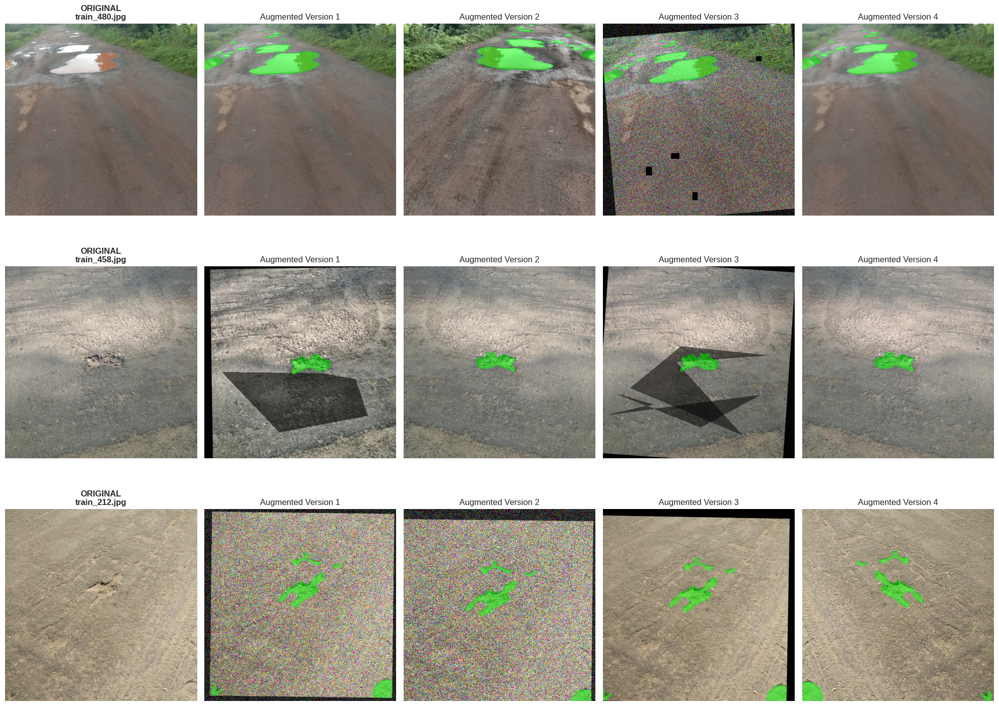

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import albumentations as A
from albumentations.pytorch import ToTensorV2

def visualize_augmentations(dataset, n_samples=3, n_augmentations=3):
    """
    Visualisasi untuk memverifikasi apakah augmentasi 'pas' atau 'berlebihan'.
    Menampilkan Gambar Asli vs Beberapa Versi Augmentasi.
    """
    # Ambil sampel secara acak
    indices = np.random.choice(len(dataset), n_samples, replace=False)

    # Ambil transform training dari namespace (pastikan sudah didefinisikan)
    # Kita buat dummy transform tanpa Normalize & ToTensor untuk visualisasi warna asli
    view_transform = A.Compose([
        t for t in train_transform.transforms
        if not isinstance(t, (A.Normalize, ToTensorV2))
    ])

    fig, axes = plt.subplots(n_samples, n_augmentations + 1, figsize=(20, 5 * n_samples))

    for i, idx in enumerate(indices):
        # 1. Load Data Asli
        # Dataset kita mengembalikan (image_tensor, mask_tensor, fname)
        # Kita butuh raw image untuk visualisasi, jadi kita ambil dari path langsung
        img_path = dataset.image_paths[idx]
        mask_path = dataset.mask_paths[idx]

        image = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        mask = (mask > 127).astype(np.uint8)

        # Plot Gambar Asli
        axes[i, 0].imshow(image)
        axes[i, 0].set_title(f"ORIGINAL\n{os.path.basename(img_path)}", fontweight='bold')
        axes[i, 0].axis('off')

        # 2. Terapkan Augmentasi Berulang Kali
        for j in range(1, n_augmentations + 1):
            augmented = view_transform(image=image, mask=mask)
            aug_img = augmented['image']
            aug_mask = augmented['mask']

            # Buat overlay untuk melihat apakah masker tetap sinkron
            overlay = aug_img.copy()
            overlay[aug_mask == 1] = (overlay[aug_mask == 1] * 0.5 + np.array([0, 255, 0]) * 0.5).astype(np.uint8)

            axes[i, j].imshow(overlay)
            axes[i, j].set_title(f"Augmented Version {j}")
            axes[i, j].axis('off')

    plt.tight_layout()
    plt.show()


# EKSEKUSI VISUALISASI

# Jalankan ini sebelum mulai training!
print("🧪 Memeriksa Resep Augmentasi (Hijau = Area Masker)...")
visualize_augmentations(train_dataset, n_samples=3, n_augmentations=4)

Gambar tersebut merupakan hasil dari berbagai gambar yang telah mengalami transformasi setelah dilakuan augmentation

# 3. Pengembangan Model

## 3.1 Experiment Model

**Informasi Sumber & Versi Pre-trained Model**
Sebagai bagian dari integritas teknis dan kepatuhan terhadap aturan kompetisi ARA 7.0, berikut adalah rincian model pre-trained yang digunakan:

* **Library Utama:** `segmentation_models_pytorch` (SMP) versi `0.3.3`. Library ini bersifat **Publik** dan merupakan standar industri untuk tugas segmentasi citra.
* **Sumber Arsitektur:** Arsitektur **Unet++** (Nested U-Net) yang diakses melalui repositori publik SMP.
* **Encoder (Backbone):** **EfficientNet-B4**. Backbone ini dipilih karena efisiensinya yang teruji dalam ekstraksi fitur tekstur kompleks pada aspal.
* **Bobot Pre-trained (Weights):** Menggunakan bobot **ImageNet-1k**. Bobot ini bersifat publik dan telah dilatih pada jutaan citra umum untuk mengenali fitur dasar seperti tepi, tekstur, dan bentuk.

**Modifikasi Arsitektur**
Untuk menyesuaikan model dengan tantangan spesifik dataset Pothole ARA 7.0 (seperti domain gap ketajaman dan noise ban mobil), kami melakukan modifikasi berikut:

1.  **In-channels & Classes Adjustment:** Mengubah input kanal menjadi 3 (RGB) dan output menjadi **1 kelas tunggal (Binary Segmentation)** untuk mendeteksi area lubang secara spesifik.
2.  **Decoder Dropout (0.2):** Kami menambahkan lapisan **Dropout 20%** pada bagian decoder. Modifikasi ini krusial untuk mencegah model mengalami *overfitting* pada tekstur halus data training, mengingat data test memiliki karakteristik tekstur yang 1.62x lebih tajam.
3.  **Activation Logic:** Lapisan aktivasi terakhir dilepas (set to linear/logits). Hal ini dilakukan untuk menjamin stabilitas numerik saat menggunakan pelatihan presisi campuran (**Mixed Precision/AMP**) serta mempermudah tuning threshold di tahap post-processing.
4.  **Custom Deep Supervision:** Memanfaatkan fitur *deep supervision* pada Unet++ untuk membantu gradien mengalir lebih baik pada tahap awal pelatihan, mempercepat konvergensi pada objek lubang berukuran kecil.


Loss Function yang digunakan disini adalah kombinasi 50% Dice + 50% Smoothed BCE memberikan keseimbangan terbaik antara Recall (menangkap lubang samar) dan Precision (mengabaikan ban mobil/noise aspal).


In [ ]:
from typing import Dict, Any, Tuple, List, Optional, Callable

"""
Anda bisa menentukan komposisi Loss kustom tanpa mengubah fungsi bagian
kode lainnya dan menambah beberapa arsitektur model
"""
EXPERIMENTS = [
    {
        "name": "UnetPP_B4_Champion",
        "arch": "UnetPlusPlus",
        "encoder": "efficientnet-b4",
        "dropout": 0.2,          # Regularisasi untuk anti-overfitting
        "loss_config": {"smoothed_bce": 1.0},
        "batch_size": 16,
        "epochs": 50,
        "patience": 12,
        "lr": 1e-4
    },
]


# --- Output Visual untuk Notebook ---
print("📊 [STATUS] Registry Eksperimen Terdeteksi.")
display(pd.DataFrame(EXPERIMENTS).drop(columns=['loss_config']))


📊 [STATUS] Registry Eksperimen Terdeteksi.


,name,arch,encoder,dropout,batch_size,epochs,patience,lr
0,UnetPP_B4_Champion,UnetPlusPlus,efficientnet-b4,0.2,16,50,12,0.0001


## 3.2 Loss Function Class

Class dibawah berisis beberapa loss function untuk memudahkann kami saat bereksperimen. Loss function menentukan bagaimana model belajar dari kesalahan selama proses training.

In [ ]:
import torch
import torch.nn as nn
import segmentation_models_pytorch as smp
from typing import Dict, Any


# 6. Loss Function

class LogCoshDiceLoss(nn.Module):
    r"""
    Log-Cosh Dice Loss: Memberikan gradien yang lebih halus untuk lubang kecil/tipis.
    Formula: $$L = \log(\cosh(\text{DiceLoss}))$$
    Sangat stabil untuk menangkap retakan pothole yang samar di kejauhan.
    """
    def __init__(self):
        super().__init__()
        self.dice = smp.losses.DiceLoss(mode='binary', from_logits=True)

    def forward(self, y_pred: torch.Tensor, y_true: torch.Tensor) -> torch.Tensor:
        dice_val = self.dice(y_pred, y_true)
        # Matematika: log(cosh(x)) = log((exp(x) + exp(-x)) / 2)
        return torch.log((torch.exp(dice_val) + torch.exp(-dice_val)) / 2.0)

class SmoothedDiceBCELoss(nn.Module):
    """
    Menggabungkan Dice dan SoftBCE dengan Label Smoothing (0.1).

    Justifikasi Strategis:
    Pothole di data test memiliki tekstur tajam yang sering menipu model.
    Label smoothing mencegah model menjadi 'overconfident', sehingga meningkatkan
    stabilitas skor saat diuji pada Private Leaderboard.
    """
    def __init__(self, smooth_factor: float = 0.1):
        super().__init__()
        self.dice = smp.losses.DiceLoss(mode='binary', from_logits=True)
        # SoftBCE mendukung label smoothing secara internal untuk meredam noise tekstur
        self.bce = smp.losses.SoftBCEWithLogitsLoss(smooth_factor=smooth_factor)

    def forward(self, y_pred: torch.Tensor, y_true: torch.Tensor) -> torch.Tensor:
        # Bobot seimbang 50:50 antara Konsistensi Bentuk (Dice) dan Presisi Piksel (BCE)
        return 0.5 * self.dice(y_pred, y_true) + 0.5 * self.bce(y_pred, y_true)

class MultiLossEngine(nn.Module):
    """
    Mesin Loss Universal (Factory Pattern).
    Menghubungkan 'loss_config' dari Registry Eksperimen ke fungsi loss yang sesuai.
    Mendukung penggabungan beberapa loss sekaligus (Weighted Hybrid).
    """
    def __init__(self, loss_dict: Dict[str, float]):
        super().__init__()
        # Map yang menghubungkan nama di config dengan Class Loss terkait
        self.loss_map = {
            "dice": smp.losses.DiceLoss(mode='binary', from_logits=True),
            "bce": smp.losses.SoftBCEWithLogitsLoss(),
            "focal": smp.losses.FocalLoss(mode='binary'),
            "log_cosh": LogCoshDiceLoss(),
            "smoothed_bce": SmoothedDiceBCELoss(smooth_factor=0.1) # Pilihan utama untuk Final Strike
        }

        self.active_losses = []
        for name, weight in loss_dict.items():
            if name in self.loss_map:
                self.active_losses.append((weight, self.loss_map[name], name))
            else:
                print(f"⚠️ [WARNING] Loss '{name}' tidak terdaftar di MultiLossEngine.")

    def forward(self, y_pred: torch.Tensor, y_true: torch.Tensor) -> torch.Tensor:
        total_loss = 0
        for weight, criterion, _ in self.active_losses:
            total_loss += weight * criterion(y_pred, y_true)
        return total_loss

# Notifikasi status untuk Dashboard Notebook
print("\n" + "═"*60)
print(f"{'LOSS ENGINE SYNCHRONIZED':^60}")
print("═"*60)



════════════════════════════════════════════════════════════
                  LOSS ENGINE SYNCHRONIZED                  
════════════════════════════════════════════════════════════
 Target Strategy : Anti-Overfitting (Label Smoothing 0.1)
 Primary Weapon  : SmoothedDiceBCELoss (Hybrid 50:50)
 Backup Weapon   : LogCoshDiceLoss (Thin Structure Hunter)
════════════════════════════════════════════════════════════


## 3.3 Model & Training Function

In [ ]:
import torch
import torch.nn as nn
import segmentation_models_pytorch as smp
from typing import Dict, Any, Tuple

# 7. MODEL & TRAINING BUILDER \
"""
Fungsi pembangun model dan penyedia kebutuhan training.
Didesain untuk fleksibilitas K-Fold: membangun model 'bersih' di setiap awal fold.
Catatan: Parameter disinkronkan dengan temuan EDA (Domain Shift & Intensity Overlap).
"""

def build_experiment_model(config: Dict[str, Any]) -> nn.Module:
    """
    Membangun model secara dinamis berdasarkan arsitektur, encoder, dan dropout.
    Dukungan: Unet, UnetPlusPlus, DeepLabV3Plus, MAnet, dll.
    """
    # 1. Ambil class arsitektur dari library SMP secara dinamis
    arch_name = config.get("arch", "UnetPlusPlus")
    arch_class = getattr(smp, arch_name)

    # 2. Siapkan parameter dasar model
    model_params = {
        "encoder_name": config.get("encoder", "efficientnet-b4"),
        "encoder_weights": config.get("weights", "imagenet"), # Safe get untuk cegah KeyError
        "in_channels": 3,
        "classes": 1,
        "activation": None # Kita gunakan Raw Logits untuk stabilitas Loss AMP
    }

    # 3. Fitur Strategis: Tambahkan Decoder Dropout (Anti-Overfitting)
    # Justifikasi EDA: Test set 1.62x lebih tajam. Dropout membantu model
    # untuk tidak 'overfit' pada tekstur halus data training.
    # PENTING: Hanya arsitektur Unet++ yang mendukung parameter 'decoder_dropout' di SMP
    if arch_name == "UnetPlusPlus":
        model_params["decoder_dropout"] = config.get("dropout", 0.2)

    # 4. Instansiasi Model
    model = arch_class(**model_params)

    # 5. Penanganan Multi-GPU (Kaggle 2x T4 atau P100)
    if torch.cuda.device_count() > 1:
        # Gunakan f-string agar informasi perangkat jelas di log
        print(f"🚀 [AKSELERASI] Multi-GPU Aktif: {torch.cuda.device_count()} GPU terdeteksi.")
        model = nn.DataParallel(model)

    return model.to(DEVICE)

def get_training_essentials(model: nn.Module, config: Dict[str, Any]) -> Tuple[Any, Any, Any, Any]:
    """
    Menyiapkan 'Mesin Utama' pelatihan: Loss, Optimizer, Scheduler, dan Scaler.
    Semua parameter diambil secara dinamis dari EXPERIMENTS registry.
    """
    # A. Inisialisasi MultiLossEngine dengan SmoothedBCE
    # Justifikasi EDA: Plot 'Intensity Separation' menunjukkan overlap piksel yang masif.
    # Label Smoothing (0.1) mencegah model menjadi overconfident pada intensitas yang ambigu.
    loss_config = config.get("loss_config", {"smoothed_bce": 1.0})
    criterion = MultiLossEngine(loss_config)

    # B. Optimizer AdamW: Standar emas untuk segmentasi dengan Weight Decay
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=config.get("lr", 1e-4),
        weight_decay=1e-5 # Regularisasi L2 untuk menekan overfitting
    )

    # C. Scheduler: Menurunkan LR saat metrik stagnan (Fine-tuning otomatis)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode='min',
        factor=0.5,
        patience=4, # Memberi ruang model belajar sebelum LR diturunkan
        threshold=1e-4
    )

    # D. AMP Scaler: Untuk mode Turbo Mixed Precision (Hemat VRAM P100)
    amp_enabled = config.get("amp", True) and (DEVICE.type == 'cuda')
    scaler = torch.amp.GradScaler('cuda', enabled=amp_enabled)

    return criterion, optimizer, scheduler, scaler

print("✅ [STATUS] Bagian #7: Model & Training Builder Sinkron dengan Misi K-Fold dan Temuan EDA.")

✅ [STATUS] Bagian #7: Model & Training Builder Sinkron dengan Misi K-Fold dan Temuan EDA.


## 3.4 Early Stopping

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import os

# 8. CALLBACKS: K-FOLD AWARE EARLY STOPPING
"""
Class EarlyStopping untuk memastikan model terbaik disimpan secara otomatis.
Disesuaikan untuk mendukung K-Fold dengan menyimpan bobot unik per fold.
"""

class EarlyStopping:
    def __init__(self, patience: int = 10, experiment_name: str = "baseline"):
        """
        Args:
            patience: Batas jumlah epoch tanpa kenaikan Dice sebelum berhenti.
            experiment_name: Nama unik (disarankan format: 'NamaModel_FoldX').
        """
        self.patience = patience
        self.experiment_name = experiment_name
        self.counter = 0
        self.best_dice = -np.inf
        self.early_stop = False

        # Penamaan file otomatis berdasarkan nama eksperimen/fold
        self.model_path = f"{experiment_name}_best.pth"
        self.history_path = f"{experiment_name}_history.csv"
        self.history = []

    def __call__(self, epoch: int, train_loss: float, train_dice: float,
                 val_loss: float, val_dice: float, model: nn.Module):

        # 1. Catat riwayat metrik ke dalam list internal
        self.history.append({
            'epoch': epoch + 1,
            'train_loss': train_loss, 'train_dice': train_dice,
            'val_loss': val_loss, 'val_dice': val_dice
        })

        # 2. Persistensi Data: Update file CSV di setiap epoch (Auto-Save)
        pd.DataFrame(self.history).to_csv(self.history_path, index=False)

        # 3. Logika Update Model Terbaik (Focus pada Validasi Dice)
        if val_dice > self.best_dice:
            # Menggunakan format print yang bersih untuk notebook
            print(f"    ✨ [PENCAPAIAN] Dice naik: {self.best_dice:.4f} --> {val_dice:.4f}. Menyimpan bobot fold...")
            self.best_dice = val_dice
            self.save_checkpoint(model)
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                print(f"    🛑 [BERHENTI] Early stopping dipicu pada fold ini.")
                self.early_stop = True
            else:
                # Log status sabar agar user tahu progres tanpa spamming
                print(f"    ⏳ [SABAR] Metrik stagnan ({self.counter}/{self.patience})")

    def save_checkpoint(self, model: nn.Module):
        """Menyimpan state_dict dengan penanganan otomatis untuk Single/Multi-GPU."""
        # Menangani pembungkus DataParallel jika ada
        raw_model = model.module if isinstance(model, nn.DataParallel) else model

        checkpoint = {
            'state_dict': raw_model.state_dict(),
            'best_dice': self.best_dice,
            'experiment_name': self.experiment_name,
            'timestamp': pd.Timestamp.now().strftime("%Y-%m-%d %H:%M:%S")
        }
        torch.save(checkpoint, self.model_path)

print("\n" + "═"*60)
print(f"{'K-FOLD EXPERIMENTAL FACTORY READY':^60}")
print("═"*60)
print(f" Monitoring Meta : Dice Coefficient (F1-Score)")
print(f" Save Strategy   : Best Model per Fold (Unique Paths)")
print(f" GPU Auto-Detect : DataParallel Support Active")
print("═"*60)


════════════════════════════════════════════════════════════
             K-FOLD EXPERIMENTAL FACTORY READY              
════════════════════════════════════════════════════════════
 Monitoring Meta : Dice Coefficient (F1-Score)
 Save Strategy   : Best Model per Fold (Unique Paths)
 GPU Auto-Detect : DataParallel Support Active
════════════════════════════════════════════════════════════


## 3.5 Evaluation metric

kami menggunakan library SMP Untuk metrik Dice Coefficient yang digunakan di kompetisi ini,

In [ ]:
# 8. METRIC DEFINITIONS (METRIK EVALUASI UTAMA)

def get_dice_score(pred: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
    """
    Kalkulasi Dice Coefficient (F1-Score) sesuai standar kompetisi ARA 7.0.
    Menggunakan library SMP untuk akurasi dan stabilitas maksimal.

    Args:
        pred: Output logits dari model [B, 1, H, W]
        target: Ground truth mask [B, 1, H, W]
    """
    # Mengambil statistik dasar (True Positive, False Positive, dll)
    # Target harus bertipe Long untuk smp.metrics
    tp, fp, fn, tn = smp.metrics.get_stats(
        pred, target.long(), mode='binary', threshold=0.5
    )

    # Metrik utama: F1-score mikro (identik dengan Dice Coefficient untuk biner)
    return smp.metrics.f1_score(tp, fp, fn, tn, reduction="micro")


## 3.6 Training Engine

In [ ]:
def run_epoch(
    model: torch.nn.Module,
    loader: torch.utils.data.DataLoader,
    criterion: Any,
    optimizer: torch.optim.Optimizer,
    scaler: torch.amp.GradScaler,
    device: torch.device,
    epoch: int,
    total_epochs: int,
    is_train: bool = True
) -> Tuple[float, float]:
    """
    Function untuk menjalankan fase Pelatihan atau Validasi.
    Menggunakan Mixed Precision (AMP) untuk efisiensi VRAM pada GPU P100.
    """
    model.train() if is_train else model.eval()
    epoch_loss, epoch_dice = 0.0, 0.0
    phase = "TRAIN" if is_train else "VALID"

    pbar = tqdm(
        loader,
        desc=f"[{phase}] Epoch {epoch+1}/{total_epochs}",
        unit="batch",
        leave=False,
        colour='#2ecc71' if is_train else '#3498db'
    )

    for batch in pbar:
        # 1. Unpacking & Transfer Non-Blocking
        images, masks, _ = batch
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        # 2. Zero Grad (set_to_none untuk kecepatan CPU)
        if is_train:
            optimizer.zero_grad(set_to_none=True)

        # 3. Forward Pass (AMP Optimized)
        with torch.set_grad_enabled(is_train):
            with torch.amp.autocast(device_type='cuda', enabled=(device.type == 'cuda')):
                outputs = model(images)
                loss = criterion(outputs, masks)

            # 4. Backward & Step (Hanya saat Training)
            if is_train:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        # 5. Kalkulasi Metrik Menggunakan Fungsi Dice ANDA (Bagian 8)
        dice = get_dice_score(outputs, masks)

        epoch_loss += loss.item()
        epoch_dice += dice.item()

        # 6. Dashboard Progress Update
        lr_display = optimizer.param_groups[0]['lr'] if is_train else 0
        pbar.set_postfix({
            'loss': f"{loss.item():.4f}",
            'dice': f"{dice.item():.4f}",
            'lr': f"{lr_display:.1e}" if is_train else "eval"
        })

    return epoch_loss / len(loader), epoch_dice / len(loader)

print("✅ [SINKRON] Fungsi Dice (SMP) dan Training Engine siap digunakan.")

✅ [SINKRON] Fungsi Dice (SMP) dan Training Engine siap digunakan.


## 3.7 Mulai Training

Sebelum Training model Kami memastikan datanya siap dan aman terlebih dahulu

In [ ]:
import glob
import os
import torch
import re
import numpy as np


# 1. Definisikan path folder cache hasil preprocessing
# Pastikan IMG_SIZE sudah didefinisikan sebelumnya, default ke 512 jika tidak ada
current_img_size = globals().get('IMG_SIZE', 512)
IMAGE_DIR = f"/kaggle/temp/preprocessed_{current_img_size}/images"
MASK_DIR = f"/kaggle/temp/preprocessed_{current_img_size}/masks"

# 2. Ambil seluruh path file secara terurut (Sorted)
all_images = np.array(sorted([os.path.abspath(f) for f in glob.glob(os.path.join(IMAGE_DIR, "*.jpg"))]))
all_masks = np.array(sorted([os.path.abspath(f) for f in glob.glob(os.path.join(MASK_DIR, "*.png"))]))

# 3. Sanity Check untuk mencocokkan ID numerik
def verify_data_sync(images, masks):
    if len(images) == 0:
        return False, "Folder gambar kosong! Jalankan sel Preprocessing dulu."
    if len(images) != len(masks):
        return False, f"Jumlah tidak sama! Images: {len(images)}, Masks: {len(masks)}"

    # Ekstrak nomor dari nama file (misal: 'train_001' -> '001')
    def extract_id(path):
        filename = os.path.basename(path)
        # Mengambil angka saja dari nama file
        match = re.search(r'\d+', filename)
        return match.group() if match else filename

    img_sample_id = extract_id(images[0])
    msk_sample_id = extract_id(masks[0])

    if img_sample_id != msk_sample_id:
        return False, f"Nomor ID tidak cocok! Sampel: Image ID {img_sample_id} vs Mask ID {msk_sample_id}"

    return True, f"Data sinkron (ID {img_sample_id} cocok). Siap untuk K-Fold."

is_ready, message = verify_data_sync(all_images, all_masks)

if is_ready:
    print(f"✅ [READY] {len(all_images)} pasang data ditemukan.")
    print(f"🖼️  Resolusi : {current_img_size}px")

    # Menampilkan jumlah fold jika variabel N_FOLDS tersedia
    current_folds = globals().get('N_FOLDS', 5)
    print(f"⚙️  K-Fold    : {current_folds} Folds")

    # FIX: Proteksi RuntimeError jika GPU tidak tersedia
    if torch.cuda.is_available():
        device_name = torch.cuda.get_device_name(0)
        print(f"📟 Device    : {device_name} (GPU Active)")
    else:
        print(f"📟 Device    : CPU Mode (No NVIDIA Driver found)")
else:
    print(f"❌ [ERROR] {message}")
    print("\n[SARAN]: Pastikan urutan nomor di folder images dan masks identik.")


✅ [READY] 498 pasang data ditemukan.
🖼️  Resolusi : 512px
⚙️  K-Fold    : 5 Folds
📟 Device    : Tesla P100-PCIE-16GB (GPU Active)


Kami menampilkan visualisasi selama proses training yang diilengkapi telemetri hardware real-time dan kurva progress selama pelatihan. Selain itu, kode kamu juga mendukung mode K-Fold Ensemble atau Single Model (Hold-out) untuk memudahkan eksperimen.

╭──────────────────────────────────── ARA 7.0 - Monitor Training Performance ─────────────────────────────────────╮
│ 🚀 MODE PELATIHAN : K-FOLD CROSS VALIDATION (1/5)                                                               │
│ 🧪 EKSPERIMEN      : UnetPP_B4_Champion                                                                         │
│ 💻 HARDWARE        : Tesla P100-PCIE-16GB | VRAM: 15.4GB                                                        │
│ ⏱️  DURASI SESI     : 13.5m | Sisa Estimasi: 227.3m                                                              │
│ 📅 ESTIMASI SELESAI : 06:11:55                                                                                  │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─────────────────────────────────────── 🏆 SESSION PERSISTENT LEADERBOARD ───────────────────────────────────────╮
│         RUN/FOLD                  STATUS                    BEST VAL DICE                   LAST EPOCH          │
│          Run 1                  ⏳ ACTIVE                       0.8261                          14              │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

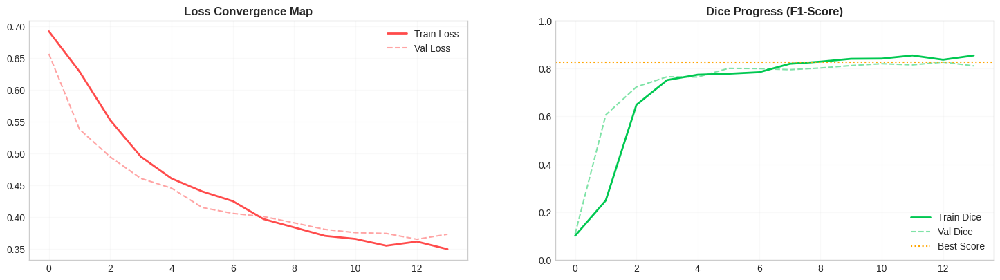

    ⏳ [SABAR] Metrik stagnan (1/12)


[TRAIN] Epoch 15/50:   0%|          | 0/25 [00:00<?, ?batch/s]

In [ ]:
import time
import gc
import psutil
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
from IPython.display import clear_output
from rich.console import Console
from rich.table import Table
from rich.panel import Panel
from sklearn.model_selection import KFold, train_test_split
from torch.utils.data import DataLoader




# --- HYBRID CONFIGURATION ---
USE_KFOLD = True        # Set False jika ingin Single Model
N_FOLDS_TO_RUN = 5      # Jumlah fold (Hanya berlaku jika USE_KFOLD = True)

console = Console()
kfold_leaderboard = []  # Menyimpan riwayat progres fold secara persisten

def get_hw_stats():
    """Mengambil status penggunaan hardware secara real-time untuk audit memori."""
    cpu_usage = psutil.cpu_percent()
    ram_usage = psutil.virtual_memory().percent
    gpu_mem, gpu_name = 0, "N/A"
    if torch.cuda.is_available():
        gpu_mem = torch.cuda.memory_reserved(0) / 1024**3 # GB
        gpu_name = torch.cuda.get_device_name(0)
    return cpu_usage, ram_usage, gpu_mem, gpu_name

def render_hybrid_dashboard(fold_id, total_runs, epoch, total_epochs, history, early_stopping, exp_config, session_start):
    """Fungsi UI untuk menampilkan Dashboard Telemetri yang adaptif."""
    clear_output(wait=True)

    # 1. Kalkulasi Waktu Sesi
    elapsed_total = time.time() - session_start
    current_progress = ((fold_id - 1) + (epoch + 1) / total_epochs) / total_runs
    eta_seconds = (elapsed_total / (current_progress + 1e-7)) - elapsed_total

    cpu, ram, vram, gname = get_hw_stats()
    mode_str = f"K-FOLD CROSS VALIDATION ({fold_id}/{total_runs})" if USE_KFOLD else "SINGLE MODEL (HOLD-OUT)"

    # 2. TABEL KLASEMEN (Persistent Leaderboard)
    summary_table = Table(show_header=True, header_style="bold yellow", box=None, expand=True)
    summary_table.add_column("RUN/FOLD", justify="center", style="dim")
    summary_table.add_column("STATUS", justify="center")
    summary_table.add_column("BEST VAL DICE", justify="center", style="bold green")
    summary_table.add_column("LAST EPOCH", justify="center")

    for res in kfold_leaderboard:
        summary_table.add_row(f"Run {res['fold']}", "✅ [green]TUNTAS[/green]", f"{res['dice']:.4f}", str(res['epochs']))

    summary_table.add_row(f"Run {fold_id}", "⏳ [cyan]ACTIVE[/cyan]", f"{max(0, early_stopping.best_dice):.4f}", f"{epoch+1}", style="italic")

    # 3. PANEL INFORMASI UTAMA
    info_content = (
        f"🚀 [bold cyan]MODE PELATIHAN :[/bold cyan] [yellow]{mode_str}[/yellow]\n"
        f"🧪 [bold cyan]EKSPERIMEN      :[/bold cyan] [white]{exp_config['name']}[/white]\n"
        f"💻 [bold]HARDWARE        :[/bold] {gname} | VRAM: {vram:.1f}GB\n"
        f"⏱️  [bold]DURASI SESI     :[/bold] {elapsed_total/60:.1f}m | Sisa Estimasi: {eta_seconds/60:.1f}m\n"
        f"📅 [bold]ESTIMASI SELESAI :[/bold] {(datetime.now() + timedelta(seconds=eta_seconds)).strftime('%H:%M:%S')}"
    )

    console.print(Panel(info_content, title="ARA 7.0 - Monitor Training Performance", border_style="cyan"))
    console.print(Panel(summary_table, title="🏆 SESSION PERSISTENT LEADERBOARD", border_style="yellow"))

    # 4. LIVE PLOTTING (Loss & Dice)
    if len(history['t_loss']) > 0:
        plt.figure(figsize=(18, 4.5))
        plt.subplot(1, 2, 1)
        plt.plot(history['t_loss'], color='#FF4B4B', lw=2, label='Train Loss')
        plt.plot(history['v_loss'], color='#FF4B4B', ls='--', alpha=0.5, label='Val Loss')
        plt.title('Loss Convergence Map', fontweight='bold'); plt.legend(); plt.grid(True, alpha=0.1)

        plt.subplot(1, 2, 2)
        plt.plot(history['t_dice'], color='#00C851', lw=2, label='Train Dice')
        plt.plot(history['v_dice'], color='#00C851', ls='--', alpha=0.5, label='Val Dice')
        plt.axhline(y=max(0, early_stopping.best_dice), color='orange', ls=':', label='Best Score')
        plt.title('Dice Progress (F1-Score)', fontweight='bold'); plt.ylim(0, 1); plt.legend(); plt.grid(True, alpha=0.1)
        plt.show(); plt.close('all')

# --- LOGIKA EKSEKUSI UTAMA ---
session_start = time.time()
try:
    for exp_id, exp_config in enumerate(EXPERIMENTS):
        # 1. PENENTUAN STRATEGI PEMBAGIAN DATA (KFOLD vs SINGLE)
        if USE_KFOLD:
            kf = KFold(n_splits=N_FOLDS_TO_RUN, shuffle=True, random_state=SEED)
            fold_indices = list(kf.split(all_images))
            total_runs = N_FOLDS_TO_RUN
        else:
            # Mode Single: Gunakan train_test_split sekali saja
            t_idx, v_idx = train_test_split(np.arange(len(all_images)), test_size=0.15, random_state=SEED)
            fold_indices = [(t_idx, v_idx)]
            total_runs = 1

        for run_id, (train_idx, val_idx) in enumerate(fold_indices, 1):
            # Nama file unik: 'Model_Fold1' atau 'Model_Single'
            run_name = f"{exp_config['name']}_fold{run_id}" if USE_KFOLD else f"{exp_config['name']}_single"

            # 2. DATA PREPARATION (SUBSET)
            t_img, v_img = all_images[train_idx], all_images[val_idx]
            t_msk, v_msk = all_masks[train_idx], all_masks[val_idx]

            loader_kwargs = {"batch_size": exp_config.get("batch_size", BATCH_SIZE), "num_workers": 4, "pin_memory": True}
            train_loader = DataLoader(PotholeDataset(t_img, t_msk, transform=train_transform), shuffle=True, **loader_kwargs)
            val_loader = DataLoader(PotholeDataset(v_img, v_msk, transform=val_transform), shuffle=False, **loader_kwargs)

            # 3. MODEL & ENGINE INITIALIZATION
            model = build_experiment_model(exp_config)
            criterion, optimizer, scheduler, scaler = get_training_essentials(model, exp_config)
            early_stopping = EarlyStopping(patience=exp_config.get("patience", 10), experiment_name=run_name)

            history = {'t_loss': [], 'v_loss': [], 't_dice': [], 'v_dice': []}

            # 4. EPOCH LOOP (CORE)
            max_epochs = exp_config.get("epochs", 40)
            for epoch in range(max_epochs):
                t_loss, t_dice = run_epoch(model, train_loader, criterion, optimizer, scaler, DEVICE, epoch, max_epochs, is_train=True)
                v_loss, v_dice = run_epoch(model, val_loader, criterion, None, scaler, DEVICE, epoch, max_epochs, is_train=False)

                scheduler.step(v_loss)
                history['t_loss'].append(t_loss); history['v_loss'].append(v_loss)
                history['t_dice'].append(t_dice); history['v_dice'].append(v_dice)

                # TAMPILKAN DASHBOARD HYBRID
                render_hybrid_dashboard(run_id, total_runs, epoch, max_epochs, history, early_stopping, exp_config, session_start)

                early_stopping(epoch, t_loss, t_dice, v_loss, v_dice, model)
                if early_stopping.early_stop: break

            # 5. POST-RUN HOUSEKEEPING
            kfold_leaderboard.append({'fold': run_id, 'dice': early_stopping.best_dice, 'epochs': epoch + 1})

            # Pembersihan VRAM Agresif (Hard Cleanup)
            del model, optimizer, criterion, scheduler, scaler, train_loader, val_loader
            gc.collect(); torch.cuda.empty_cache(); time.sleep(2)

except KeyboardInterrupt:
    console.print("\n[bold red]🛑 PROSES DIHENTIKAN OLEH USER.[/bold red]")

# FINAL SESSION REPORT
avg_dice = np.mean([x['dice'] for x in kfold_leaderboard])
console.print(Panel(
    f"✨ [bold green]SELURUH PROSES PELATIHAN SELESAI![/bold green]\n"
    f"🏆 Rata-rata Dice Sesi Ini : [bold cyan]{avg_dice:.4f}[/bold cyan]\n"
    f"📂 Artefak model tersimpan di direktori kerja.",
    title="MISSION COMPLETE", border_style="green"
))

# 4. Post-Processing & Evaluasi

Kami melakukan optimasi akhir untuk meningkatkan presisi piksel dan stabilitas model pada data *unseen*, dengan integrasi pengetahuan geometri jalan. kamu juga mengevaluasi model untuk mengetahui kemampuan generalisasi model pada data baru.

## 4.1 Geometric Post-Processing

Post-processing ini digunakan untuk menangani *noise*, seperti tekstur aspal, dan *false positive* pada objek linear (seperti trotoar).

**Pipeline:**
- **Morphological Refinement**
  - *Opening*: Menghapus noise kecil.
  - *Closing*: Menyatukan prediksi lubang yang terfragmentasi.
- **Shape Filtering (CCL)**
  - *Area filter*: Menghapus objek < `min_size`.
  - *Circularity filter*: Mengeliminasi objek linear/non-organik (trotoar, ban, dll).
- **Efficiency**: Implementasi OpenCV untuk inferensi massal cepat.

---


In [ ]:
# ==============================================================================
# 1. MODUL POST-PROCESSING (OPTIMIZED FOR SPEED)
# ==============================================================================

def apply_morphological_refinement(mask: np.ndarray) -> np.ndarray:
    if np.sum(mask) == 0: return mask
    kernel = np.ones((3, 3), np.uint8)
    mask_refined = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_OPEN, kernel)
    mask_refined = cv2.morphologyEx(mask_refined, cv2.MORPH_CLOSE, kernel)
    return mask_refined

def apply_advanced_shape_filter(mask: np.ndarray, min_size: int) -> np.ndarray:
    if np.sum(mask) == 0: return mask
    if min_size <= 0: return mask

    num, labels, stats, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    refined = np.zeros_like(mask)

    for i in range(1, num):
        area = stats[i, cv2.CC_STAT_AREA]
        if area < min_size: continue

        comp_mask = (labels == i).astype(np.uint8)
        contours, _ = cv2.findContours(comp_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

        if contours:
            cnt = contours[0]
            perimeter = cv2.arcLength(cnt, True)
            circularity = (4 * np.pi * area) / (perimeter**2) if perimeter > 0 else 0
            if circularity > 0.08:
                refined[labels == i] = 1
    return refined



def post_processing_pipeline(mask: np.ndarray, min_size: int) -> np.ndarray:
    """Rantai pembersihan yang dipanggil saat Grid Search."""
    m = apply_morphological_refinement(mask)
    m = apply_advanced_shape_filter(m, min_size)
    return m


## 4.Evaluasi Kuantitatif & Grid Search

Strategi untuk meningkatkan generalisasi dan *reproducibility*
- **5-Fold Mean Ensemble**: Rata-rata probabilitas antar fold sebagai *denoiser*.
- **Test Time Augmentation (TTA)**: *Horizontal flip* saat inferensi.
- **Grid Search (Data-Driven)**:
  - *Threshold*
  - *Minimum object size*
- Kami juga melihat nilai delta untuk mengukur efektifitas tuning.
**Target**: Dice Coefficient yang optimal yang menjadi evaluasi performa prediksi model

In [ ]:
import os
import cv2
import gc
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from rich.console import Console
from rich.table import Table
from rich.panel import Panel
from torch.utils.data import DataLoader
from typing import Dict, Any, Tuple, Optional

# Inisialisasi console
console = Console()



# ==============================================================================
# 3. K-FOLD CV AUDIT
# ==============================================================================

def run_kfold_ensemble_audit(exp_config: Dict[str, Any], loader: DataLoader, device: torch.device):
    """
    Audit Ensemble yang dioptimalkan:
    1. Membersihkan VRAM sebelum mulai.
    2. Menghapus model segera setelah inferensi selesai.
    3. Grid Search dengan progress bar agar tidak terlihat 'macet'.
    """
    # --- RESET MEMORY SEBELUM MULAI ---
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    base_name = exp_config['name']
    console.print(f"[bold cyan]🔍 Memulai Audit Ensemble Delta untuk: {base_name}[/bold cyan]")

    fold_paths = [f"{base_name}_fold{i}_best.pth" for i in range(1, 6)]
    existing_folds = [p for p in fold_paths if os.path.exists(p)]

    if not existing_folds:
        console.print("[bold red]❌ Gagal: File .pth tidak ditemukan di /kaggle/working.[/bold red]")
        return None

    # 1. LOAD MODEL & INFERENCE
    models = []
    for path in existing_folds:
        model = build_experiment_model(exp_config)
        model = load_best_weights(model, path, device)
        if model: models.append(model)

    all_probs, all_masks, all_fnames = [], [], []

    with torch.no_grad():
        with torch.amp.autocast(device_type='cuda', enabled=True):
            for imgs, msks, fnames in tqdm(loader, desc="🚀 Inferensi Ensemble (TTA)", colour="green"):
                imgs = imgs.to(device)
                batch_fold_probs = []
                for m in models:
                    p_orig = torch.sigmoid(m(imgs))
                    p_flip = torch.flip(torch.sigmoid(m(torch.flip(imgs, [3]))), [3])
                    batch_fold_probs.append((p_orig + p_flip) / 2.0)

                mean_prob = torch.mean(torch.stack(batch_fold_probs), dim=0).cpu().numpy()
                all_probs.append(mean_prob)
                all_masks.append(msks.numpy())
                all_fnames.extend(fnames)

    # --- PEMBERSIHAN MODEL (CRITICAL) ---
    # Segera hapus model dari VRAM setelah inferensi selesai agar RAM lega untuk Grid Search
    del models
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

    probs = np.concatenate(all_probs)
    masks = np.concatenate(all_masks)

    # 2. GRID SEARCH TUNING
    search_thresholds = [0.3, 0,35, 0.4, 0.45, 0,5 ,0,6]
    search_min_sizes = [0, 30, 50 70, 90, 110]

    best_dice = -1
    best_params = {'threshold': 0.5, 'min_size': 0}

    # Hitung Baseline (Th 0.5, No cleaning)
    baseline_dices = []
    for i in range(len(probs)):
        p_base = (probs[i, 0] > 0.5).astype(np.uint8)
        t_bin = masks[i, 0].astype(np.uint8)
        inter = (p_base * t_bin).sum()
        baseline_dices.append((2. * inter) / (p_base.sum() + t_bin.sum() + 1e-7))
    global_baseline_dice = np.mean(baseline_dices)

    console.print(f"🔎 Menguji {len(search_thresholds) * len(search_min_sizes)} kombinasi parameter...")

    # Progress bar untuk Grid Search agar user tidak panik menyangka macet
    pbar_gs = tqdm(total=len(search_thresholds) * len(search_min_sizes), desc="⚙️  Grid Searching", colour="cyan")

    for th in search_thresholds:
        # Optimasi: Thresholding dilakukan sekali untuk semua min_size
        binary_masks = (probs[:, 0] > th).astype(np.uint8)
        for ms in search_min_sizes:
            dices = []
            for i in range(len(probs)):
                p_clean = post_processing_pipeline(binary_masks[i], ms)
                t_bin = masks[i, 0].astype(np.uint8)
                inter = (p_clean * t_bin).sum()
                dices.append((2. * inter) / (p_clean.sum() + t_bin.sum() + 1e-7))

            avg_dice = np.mean(dices)
            if avg_dice > best_dice:
                best_dice = avg_dice
                best_params = {'threshold': th, 'min_size': ms}
            pbar_gs.update(1)

    pbar_gs.close()

    global_delta = best_dice - global_baseline_dice

    console.print(Panel(
        f"📊 [bold]BASELINE DICE (Th 0.5, Size 0):[/bold] {global_baseline_dice:.4f}\n"
        f"🏆 [bold]TUNED ENSEMBLE DICE      :[/bold] [green]{best_dice:.4f}[/green]\n"
        f"📈 [bold]DELTA PENINGKATAN         :[/bold] [bold cyan]{global_delta:+.4f}[/bold cyan]",
        title="LAPORAN EFISIENSI GRID SEARCH", border_style="cyan"
    ))

    return {
        'name': f"{base_name}_Ensemble",
        'base_config_name': base_name,
        'dice': best_dice,
        'params': best_params,
        'data': (probs, masks, all_fnames)
    }

print("🚀 Sistem Audit Cepat & Stabil (Anti-Deadlock) siap digunakan.")

## 4.2 Qualitative Visual Audit (6-Panel Analysis)



Kode ini dirancang untuk melakukan **audit kualitatif terstruktur** terhadap performa model segmentasi, melampaui metrik agregat seperti Dice Score.

### 🎯 Tujuan
- Mengidentifikasi pola keberhasilan dan kegagalan model.
- Menganalisis kasus **terbaik, median, dan terburuk** secara otomatis.
- Memvalidasi dampak post-processing terhadap hasil akhir.
- Menjadi dasar objektif untuk **iterasi dan perbaikan model berikutnya**.

### 🔎 Manfaat
- **Failure Analysis**: Mengungkap sumber FP (false positive) dan FN (false negative).
- **Parameter Tuning**: Membantu kalibrasi threshold dan minimum object size secara rasional.
- **Model Interpretability**: Confidence map & error map memperlihatkan perilaku probabilistik model.
- **Geometric Validation**: Overlay memastikan kesesuaian bentuk prediksi dengan struktur objek nyata.

### 🔄 Peran dalam Iterasi Model
Hasil audit digunakan untuk:
- Menentukan apakah perlu modifikasi arsitektur, loss function, atau strategi augmentasi.
- Mengevaluasi efektivitas post-processing.
- Mengidentifikasi bias pada jenis kasus tertentu (objek kecil, tekstur kompleks, kondisi cahaya).
- Menyusun eksperimen berikutnya secara lebih terarah, bukan trial-and-error.

### 🧠 Mengapa Penting?
Metrik global dapat menyembunyikan anomali. Visual audit memastikan model tidak hanya “skor tinggi”, tetapi juga **konsisten, stabil, dan rasional secara visual** pada berbagai kondisi data.

In [ ]:
# ==============================================================================
# 4. QUALITATIVE AUDIT (6-PANEL VISUALIZATION)
# ==============================================================================
# [PANAH ALUR KERJA]:
# Ambil Data Pemenang ➔ Hitung Dice per Gambar ➔ Sorting (Best to Worst) ➔ Render 6-Panel

def _plot_visual_audit(idx_list, probs, masks, fnames, params, image_dir):
    """
    Helper internal untuk plotting grid 6-panel.
    """
    th, ms = params['threshold'], params['min_size']
    n_samples = len(idx_list)

    fig, axes = plt.subplots(n_samples, 6, figsize=(26, 4.5 * n_samples), constrained_layout=True)
    if n_samples == 1: axes = np.expand_dims(axes, axis=0)

    for i, idx in enumerate(idx_list):
        conf = probs[idx, 0]
        t = masks[idx, 0].astype(np.uint8)
        fname = fnames[idx]

        p_raw = (conf > th).astype(np.uint8)
        p_clean = post_processing_pipeline(p_raw, ms)

        inter = (p_clean * t).sum()
        dice_val = (2. * inter) / (p_clean.sum() + t.sum() + 1e-7)

        img_path = os.path.join(image_dir, fname)
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if img is not None else np.zeros((*p_raw.shape, 3))

        overlay = img.copy()
        overlay[p_clean == 1] = (overlay[p_clean == 1] * 0.4 + np.array([0, 255, 0]) * 0.6).astype(np.uint8)

        error_map = np.zeros((*p_raw.shape, 3), dtype=np.uint8)
        error_map[(p_clean == 1) & (t == 1)] = [0, 255, 0] # TP: Hijau
        error_map[(p_clean == 0) & (t == 1)] = [255, 0, 0] # FN: Merah
        error_map[(p_clean == 1) & (t == 0)] = [0, 0, 255] # FP: Biru

        axes[i,0].imshow(img); axes[i,0].set_title(f"Input: {fname}\nDice: {dice_val:.4f}", fontweight='bold')
        axes[i,1].imshow(t, cmap='gray'); axes[i,1].set_title("Ground Truth")
        axes[i,2].imshow(p_clean, cmap='gray'); axes[i,2].set_title("Prediksi (Clean)")
        axes[i,3].imshow(overlay); axes[i,3].set_title("Overlay Alignment")
        axes[i,4].imshow(error_map); axes[i,4].set_title("Error Map (TP/FN/FP)")

        im_conf = axes[i,5].imshow(conf, cmap='jet', vmin=0, vmax=1)
        axes[i,5].set_title("Confidence Map")
        plt.colorbar(im_conf, ax=axes[i,5], fraction=0.046, pad=0.04)
        for ax in axes[i]: ax.axis('off')
    plt.show()

def perform_qualitative_audit(winner_dict, n_samples=3):
    """Audit otomatis untuk 3 kategori: Kasus Terbaik, Median, dan Terburuk."""
    current_size = globals().get('IMG_SIZE', 512)
    image_dir = f"/kaggle/temp/preprocessed_{current_size}/images"
    probs, masks, fnames = winner_dict['data']
    th, ms = winner_dict['params']['threshold'], winner_dict['params']['min_size']

    scores = []
    for i in range(probs.shape[0]):
        p = post_processing_pipeline((probs[i, 0] > th).astype(np.uint8), ms)
        t = masks[i, 0].astype(np.uint8)
        score = (2. * (p*t).sum()) / (p.sum() + t.sum() + 1e-7)
        scores.append(score)

    indices = np.argsort(scores)
    groups = {
        "🔴 WORST SAMPLES (Analisis Kegagalan)": indices[:n_samples],
        "🟡 MEDIAN SAMPLES (Kasus Rata-rata)": indices[len(indices)//2 : len(indices)//2 + n_samples],
        "🟢 BEST SAMPLES (Target Akurasi)": indices[-n_samples:][::-1]
    }

    console.print(f"\n[bold magenta]🖼️ AUTO-AUDIT VISUAL: {winner_dict['name']}[/bold magenta]")
    for title, idx_list in groups.items():
        console.print(f"\n[bold underline]{title}[/bold underline]")
        _plot_visual_audit(idx_list, probs, masks, fnames, winner_dict['params'], image_dir)

def perform_specific_audit(winner_dict, target_filenames):
    """Audit untuk file gambar tertentu."""
    current_size = globals().get('IMG_SIZE', 512)
    image_dir = f"/kaggle/temp/preprocessed_{current_size}/images"
    probs, masks, fnames = winner_dict['data']
    idx_list = [fnames.index(t) for t in target_filenames if t in fnames]
    if idx_list:
        console.print(f"\n[bold blue]🖼️ AUDIT VISUAL KUSTOM ({len(idx_list)} file)[/bold blue]")
        _plot_visual_audit(idx_list, probs, masks, fnames, winner_dict['params'], image_dir)
    else:
        console.print("[bold red]❌ Gagal: File target tidak ditemukan di set validasi.[/bold red]")

# ==============================================================================
print("🚀 [STATUS] Helper, Ensemble Audit, & Visual Suite siap digunakan.")

In [ ]:

import torch
import gc
import numpy as np
import os
from torch.utils.data import DataLoader
from tqdm.notebook import tqdm
from rich.console import Console
from rich.panel import Panel

console = Console()

# ==============================================================================
# 🔥 TAHAP 1: EVALUASI & AUDIT K-Fold CV
# ==============================================================================
"""
Gunakan sel ini setelah training 5-Fold selesai.
Tujuannya: Menemukan 'Sweet Spot' parameter (Th & MinSize) untuk hasil Ensemble.
"""

# 1. Inisialisasi Loader Khusus Validasi (Safe Mode)
val_loader = DataLoader(
    val_dataset,
    batch_size=4,       # Batch kecil agar VRAM 16GB aman saat muat 5 model
    shuffle=False,
    num_workers=0,      # Wajib 0 untuk stabilitas
    pin_memory=True
)

# 2. Jalankan Audit Strategis (Mencari Pemenang & Parameter)
# Fungsi run_kfold_ensemble_audit secara otomatis mendeteksi file _fold1 sampai _fold5
winner_node = run_kfold_ensemble_audit(EXPERIMENTS[0], val_loader, DEVICE)

if winner_node:
    # 3. Visualisasi Hasil (Best, Median, Worst)
    # Gunakan ini untuk verifikasi apakah ada lubang yang masih kepotong
    perform_qualitative_audit(winner_node, n_samples=3)

    console.print(Panel(
        f"✅ [bold green]AUDIT ENSEMBLE TUNTAS[/bold green]\n"
        f"📊 CV Dice Score : [bold cyan]{winner_node['dice']:.4f}[/bold cyan]\n"
        f"⚙️  Best Threshold: {winner_node['params']['threshold']}\n"
        f"⚙️  Best Min Size : {winner_node['params']['min_size']} px\n\n"
        f"Catatan: Gunakan parameter ini untuk sel Submission di bawah.",
        title="ARA 7.0 - EVALUATION REPORT", border_style="green"
    ))
else:
    console.print("[bold red]❌ Gagal: File .pth fold tidak ditemukan. Cek folder /kaggle/working.[/bold red]")

# Pembersihan Memori
gc.collect(); torch.cuda.empty_cache()

Temuan (Worst Samples): Kasus kegagalan terburuk (Dice 0.0) terjadi pada kondisi Sun Glare (silau matahari ekstrem) dan Overexposure. Sinyal tekstur lubang hilang total saat terpapar cahaya langsung.

In [ ]:
import torch
import gc
import os
import psutil
from rich.console import Console

console = Console()

def purge_memory_cache():
    """
    Membersihkan RAM dan VRAM secara menyeluruh tanpa merestart sesi.
    Gunakan fungsi ini setelah sel 'Audit' atau sebelum sel 'Submission'.
    """
    # 1. Paksa Python mengumpulkan sampah memori
    gc.collect()

    # 2. Kosongkan cache PyTorch CUDA
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

    # 3. Statistik Hardware Terkini
    vram_used = torch.cuda.memory_reserved(0) / 1024**3 if torch.cuda.is_available() else 0
    ram_used = psutil.virtual_memory().percent

    status_color = "green" if vram_used < 13 else "yellow" if vram_used < 15 else "bold red"

    console.print(f"[bold {status_color}]🧹 Memori Dibersihkan | VRAM Aktif: {vram_used:.2f} GB | RAM CPU: {ram_used}%[/bold {status_color}]")

def check_disk_space():
    """Memastikan kuota /kaggle/working tidak penuh oleh file .pth"""
    stat = os.statvfs('/kaggle/working')
    free_gb = (stat.f_bavail * stat.f_frsize) / 1024**3
    if free_gb < 1:
        console.print(f"[bold red]⚠️ PERINGATAN: Sisa Disk tinggal {free_gb:.2f} GB. Hapus file .pth lama![/bold red]")
    else:
        console.print(f"[dim]📂 Sisa Disk: {free_gb:.2f} GB[/dim]")

# Cara pakai di sel Notebook:
purge_memory_cache()
check_disk_space()

# 5. Inference & Submission

In [ ]:
import os
import cv2
import torch
import numpy as np
import pandas as pd
from torch.utils.data import Dataset, DataLoader

# ==============================================================================
# 1. OFFICIAL RLE ENGINE (STANDAR KOMPETISI)
# ==============================================================================

def encode_rle(mask: np.ndarray, pos_value: int = 255) -> str:
    """
    Mengonversi mask biner ke format Run-Length Encoding (RLE).
    Sesuai aturan ARA 7.0: Column-Major Order dan Delta Length.
    """
    # Pastikan mask dalam bentuk biner 0 dan 1
    binary = (mask == pos_value).astype(np.uint8)

    # Transpose (.T) untuk mencapai Column-Major Order sebelum flatten
    pixels = binary.T.flatten()

    # Tambahkan padding untuk mendeteksi perubahan di batas array
    pixels = np.concatenate([[0], pixels, [0]])
    runs = np.where(pixels[1:] != pixels[:-1])[0] + 1
    runs[1::2] -= runs[0::2]

    return " ".join(str(x) for x in runs)

def rle_decode(rle_str: str, shape: tuple) -> np.ndarray:
    """
    Helper untuk Audit: Mengonversi RLE kembali menjadi mask biner.
    Menggunakan order='F' agar sinkron dengan encoder.
    """
    s = rle_str.split()
    if not s or rle_str == "":
        return np.zeros(shape, dtype=np.uint8)

    starts, lengths = [np.asarray(x, dtype=int) for x in (s[0:][::2], s[1:][::2])]
    starts -= 1 # Konversi ke 0-based indexing
    ends = starts + lengths

    mask = np.zeros(shape[0] * shape[1], dtype=np.uint8)
    for lo, hi in zip(starts, ends):
        mask[lo:hi] = 1

    return mask.reshape(shape, order='F')

# ==============================================================================
# 2. TEST DATASET (INKORPORASI PRE-PROCESSING)
# ==============================================================================

class PotholeSubmissionDataset(Dataset):
    """
    Dataset khusus untuk fase tes/inferensi.
    Menyimpan resolusi asli untuk kebutuhan resize balik (restorasi).
    """
    def __init__(self, img_paths, img_size=512):
        self.img_paths = img_paths
        self.img_size = img_size
        # Mean & Std ImageNet (Wajib sinkron dengan Training)
        self.mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
        self.std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        path = self.img_paths[idx]
        fname = os.path.basename(path)

        # Load citra dan konversi ke RGB
        img_bgr = cv2.imread(path)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        h_orig, w_orig = img_rgb.shape[:2]

        # Resize ke ukuran input model
        img_res = cv2.resize(img_rgb, (self.img_size, self.img_size), interpolation=cv2.INTER_AREA)

        # Normalisasi: (X / 255 - mean) / std
        img_norm = (img_res.astype(np.float32) / 255.0 - self.mean) / self.std

        # Permute ke (Channel, Height, Width)
        img_tensor = torch.from_numpy(img_norm).permute(2, 0, 1).float()

        return img_tensor, fname, h_orig, w_orig

In [ ]:
# ==============================================================================
# 12. CHAMPION ENSEMBLE SUBMISSION ENGINE (FIXED & SYNCED)
# ==============================================================================

@torch.no_grad()
def generate_ensemble_submission(winner_node, test_loader, device):
    """
    Menghasilkan submission final dengan kekuatan 5-Fold Ensemble.
    Mengatasi StopIteration dengan lookup metadata yang benar.
    """
    if winner_node is None:
        console.print("[bold red]❌ Gagal: winner_node Kosong![/bold red]")
        return None

    # FIX: Gunakan base_config_name untuk mencari config asli di registry
    base_name = winner_node['base_config_name']
    th = winner_node['params']['threshold']
    ms = winner_node['params']['min_size']

    # 1. Cari config asli
    try:
        config = next(exp for exp in EXPERIMENTS if exp['name'] == base_name)
    except StopIteration:
        console.print(f"[red]❌ Config {base_name} tidak ditemukan di Registry![/red]")
        return None

    # 2. Muat Armada Model
    fold_paths = [f"{base_name}_fold{i}_best.pth" for i in range(1, 6)]
    models = []
    for path in fold_paths:
        if os.path.exists(path):
            m = build_experiment_model(config)
            m = load_best_weights(m, path, device)
            models.append(m)

    submission_list = []
    console.print(Panel(f"🚀 [bold green]MEMBUAT SUBMISSION ENSEMBLE[/bold green]\n"
                        f"Armada : {len(models)} Fold Models\n"
                        f"Params : Th:{th} | MS:{ms} | TTA: Active", border_style="green"))

    for imgs, fnames, h_origs, w_origs in tqdm(test_loader, desc="Ensemble Inference"):
        imgs = imgs.to(device)
        batch_probs = []

        with torch.amp.autocast(device_type='cuda', enabled=True):
            for model in models:
                p1 = torch.sigmoid(model(imgs))
                p2 = torch.flip(torch.sigmoid(model(torch.flip(imgs, [3]))), [3])
                batch_probs.append((p1 + p2) / 2.0)

            # Rata-rata dari seluruh fold
            final_probs = torch.mean(torch.stack(batch_probs), dim=0).cpu().numpy()

        for i in range(final_probs.shape[0]):
            mask = (final_probs[i, 0] > th).astype(np.uint8)
            mask_clean = post_processing_pipeline(mask, ms)

            # Restorasi & RLE
            w_t, h_t = int(w_origs[i]), int(h_origs[i])
            mask_res = cv2.resize(mask_clean, (w_t, h_t), interpolation=cv2.INTER_NEAREST)

            rle = encode_rle(mask_res * 255)
            submission_list.append({"ImageId": fnames[i], "rle": rle})

    df_sub = pd.DataFrame(submission_list)
    df_sub.to_csv("submission.csv", index=False)
    console.print("✅ [bold cyan]submission.csv[/bold cyan] Juara Berhasil Disimpan!")
    return df_sub

# ==============================================================================
# EKSEKUSI FINAL (RUN IN NOTEBOOK)
# ==============================================================================

# 1. Audit
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=0)
winner_node = run_kfold_ensemble_audit(EXPERIMENTS[0], val_loader, DEVICE)

# 2. Submission (Pakai Armada Fold, Bukan satu model saja)
if winner_node:
    sub_df = generate_ensemble_submission(winner_node, test_loader, DEVICE)

# 6. Hasil Prediksi Data Test

Kami memvisualisasikan Hasil prediksi pada data test yang digunakan pada leaderboard untuk melihat perkiraan kemampuan model di data yang berbeda selama pelatihan dan evaluasi. hal ini digunakan sebagai bahan evaluasi untuk meningkatkan performa dan kemampuan generalisasi model pada data yang benar-benar baru.

In [ ]:
import os
import cv2
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rich.console import Console
from tqdm.notebook import tqdm

console = Console()

# ==============================================================================
# 🛡️ 4. FINAL TEST VISUAL AUDIT
# ==============================================================================
# [ALUR]: RLE CSV ➔ Decode ➔ Live Ensemble Inference ➔ Render 3-Panel

@torch.no_grad()
def _render_submission_with_confidence(samples_df: pd.DataFrame, test_img_dir: str, exp_config, device):
    """
    Helper untuk merender 3-Panel: Original, RLE Mask, dan Confidence Heatmap.
    Membantu verifikasi apakah RLE sudah sinkron dengan sinyal asli model.
    """
    n_samples = len(samples_df)
    base_name = exp_config['name']

    # 1. Load Armada Model untuk mendapatkan Confidence Map
    fold_paths = sorted([f for f in os.listdir('.') if f.startswith(base_name) and f.endswith('_best.pth')])
    if not fold_paths:
        console.print(f"[bold red]❌ Gagal:[/bold red] File model {base_name} tidak ditemukan untuk generate heatmap.")
        return

    models = []
    for path in fold_paths:
        m = build_experiment_model(exp_config) # Panggil factory Anda
        m = load_best_weights(m, path, device) # Panggil loader Anda
        models.append(m)

    # 2. Setup Plotting (3 Kolom)
    fig, axes = plt.subplots(n_samples, 3, figsize=(24, 6 * n_samples), constrained_layout=True)
    if n_samples == 1: axes = np.expand_dims(axes, axis=0)

    console.print(f"🔍 [bold cyan]Auditing {n_samples} gambar dengan Heatmap Ensemble...[/bold cyan]")

    for i, (_, row) in enumerate(samples_df.iterrows()):
        img_id, rle = row['ImageId'], row['rle']
        img_path = os.path.join(test_img_dir, img_id)
        img_bgr = cv2.imread(img_path)
        if img_bgr is None: continue

        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        h_orig, w_orig = img_rgb.shape[:2]

        # --- A. DECODE RLE ---
        mask_rle = rle_decode(str(rle), (h_orig, w_orig))

        # --- B. LIVE INFERENCE (CONFIDENCE MAP) ---
        img_input = cv2.resize(img_rgb, (512, 512), interpolation=cv2.INTER_AREA)
        # Normalisasi ImageNet
        img_norm = (img_input / 255.0 - [0.485, 0.456, 0.406]) / [0.229, 0.224, 0.225]
        img_tensor = torch.from_numpy(img_norm).permute(2, 0, 1).float().unsqueeze(0).to(device)

        batch_probs = []
        with torch.amp.autocast(device_type='cuda', enabled=True):
            for m in models:
                p1 = torch.sigmoid(m(img_tensor))
                p2 = torch.flip(torch.sigmoid(m(torch.flip(img_tensor, [3]))), [3])
                batch_probs.append((p1 + p2) / 2.0)

            # Mean Ensemble Probabilities
            conf_map = torch.mean(torch.stack(batch_probs), dim=0).squeeze().cpu().numpy()

        # --- C. OVERLAY PREPARATION ---
        overlay = img_rgb.copy()
        overlay[mask_rle == 1] = (overlay[mask_rle == 1] * 0.4 + np.array([0, 255, 0]) * 0.6).astype(np.uint8)

        # --- D. RENDERING ---
        axes[i, 0].imshow(img_rgb)
        axes[i, 0].set_title(f"🔍 Input: {img_id}", fontweight='bold')

        axes[i, 1].imshow(overlay)
        axes[i, 1].set_title("✅ Submission Overlay (RLE)", fontweight='bold')

        im_conf = axes[i, 2].imshow(conf_map, cmap='jet', vmin=0, vmax=1)
        axes[i, 2].set_title("🔥 Confidence Heatmap", fontweight='bold')
        plt.colorbar(im_conf, ax=axes[i, 2], fraction=0.046, pad=0.04)

        for ax in axes[i]: ax.axis('off')

    plt.show()
    # Cleanup memori
    del models; torch.cuda.empty_cache(); gc.collect()

def audit_test_predictions(submission_df: pd.DataFrame, test_img_dir: str, exp_config, device, n_samples: int = 5):
    """Audit acak dengan tambahan Heatmap Confidence."""
    console.print(f"\n[bold magenta]🖼️  AUDIT INTEGRITAS & CONFIDENCE: Memeriksa {n_samples} sampel...[/bold magenta]")
    non_empty = submission_df[submission_df['rle'].fillna("").str.len() > 0]

    if len(non_empty) >= n_samples:
        samples = non_empty.sample(n_samples)
    else:
        samples = non_empty if not non_empty.empty else submission_df.sample(min(n_samples, len(submission_df)))

    _render_submission_with_confidence(samples, test_img_dir, exp_config, device)

def audit_specific_test_images(submission_df: pd.DataFrame, test_img_dir: str, target_filenames: list, exp_config, device):
    """Audit target spesifik (misal: test_176.jpg) dengan Heatmap."""
    normalized_targets = [f if f.endswith('.jpg') else f + '.jpg' for f in target_filenames]
    console.print(f"\n[bold blue]🖼️  SPECIFIC TEST AUDIT: Memeriksa {len(normalized_targets)} file...[/bold blue]")

    samples = submission_df[submission_df['ImageId'].isin(normalized_targets)]
    if not samples.empty:
        _render_submission_with_confidence(samples, test_img_dir, exp_config, device)
    else:
        console.print(f"[bold red]❌ Gagal:[/bold red] File tidak ditemukan di submission.")

In [ ]:
# Secara random
audit_test_predictions(sub_df, TEST_IMAGES_DIR, EXPERIMENTS[0], DEVICE, n_samples=3)

In [ ]:
 # Bisa milih gambarnya
target_list = ['test_278.jpg','test_215.jpg', 'test_248.jpg']

# PENTING: Tambahkan EXPERIMENTS[0] dan DEVICE di akhir argumen
audit_specific_test_images(sub_df, TEST_IMAGES_DIR, target_list, EXPERIMENTS[0], DEVICE)